
# Wilson–Cowan E–I Dynamics + Kernel Koopman Transient Spikes

This is the **second neuroscience experiment** and deliberately keeps the original
kernel/KEDMD transient-amplification framework unchanged.

We use a spatially homogeneous Wilson–Cowan-type excitatory–inhibitory population model,

\[
\tau_E \dot E
=
-E+(1-rE)\,S(w_{EE}E-w_{EI}I+P),
\]

\[
\tau_I \dot I
=
-I+(1-rI)\,S(w_{IE}E-w_{II}I+Q),
\]

with sigmoid

\[
S(u)=\frac{1}{1+\exp[-a(u-\theta)]}.
\]

Here \(E(t)\) and \(I(t)\) represent coarse-grained excitatory and inhibitory
population activities.

The parameter set below is a **controlled stable benchmark chosen for this experiment**.
It is not presented as a canonical biological parameter set.

The experiment asks:

> Can the same stable nonlinear E–I dynamics produce substantially different
> finite-time behavior when represented by different kernel Koopman surrogates?

We retain the same four kernel families:

- Laplace,
- Matérn-\(3/2\),
- Rational Quadratic,
- Gaussian RBF.

For each kernel,

\[
A_\lambda=(G_X+\lambda I)^{-1}A_X,
\]

\[
\widetilde A_\lambda
=
G_\lambda^{1/2}A_\lambda G_\lambda^{-1/2}
=
G_\lambda^{-1/2}A_XG_\lambda^{-1/2},
\]

and

\[
\|A_\lambda^n\|_{G_\lambda}
=
\|\widetilde A_\lambda^n\|_2.
\]

We compute:

1. the stable Wilson–Cowan equilibrium;
2. its exact local tangent transient gain;
3. a finite-amplitude nonlinear perturbation gain;
4. kernel Koopman transient envelopes;
5. fixed worst-direction growth;
6. Koopman surrogate pseudospectra;
7. grid-based Kreiss estimates;
8. \(10^{-2}\)- and \(10^{-3}\)-pseudospectral radii;
9. regularization sensitivity.

The physical-state transient and RKHS transient live in different spaces and are
therefore treated as **complementary diagnostics**, not numerically identical quantities.


In [1]:

# Optional only if packages are missing:
!pip3 install -U numpy scipy pandas matplotlib



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [2]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import root
from scipy.linalg import expm, eigh, solve, svdvals
from scipy.spatial.distance import cdist

np.set_printoptions(precision=6, suppress=True)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------
SEED = 42

# Physical integration / sampling
DT = 0.05
N_SUBSTEPS = 6
T_TRANSIENT = 100

# KEDMD
LAMBDA = 3e-4
TRAIN_RADIUS = 0.10

# Pseudospectrum
FAST_MODE = True

if FAST_MODE:
    M = 80
    GRID_N = 61
else:
    M = 120
    GRID_N = 101

GRID_LIM = 1.30
EPS_LEVELS = (1e-2, 1e-3)

OUTDIR = "WilsonCowan_kernel_koopman_results"
os.makedirs(OUTDIR, exist_ok=True)

print("FAST_MODE =", FAST_MODE)
print("M =", M)
print("lambda =", LAMBDA)
print("transient horizon =", T_TRANSIENT)
print("pseudospectral grid =", GRID_N, "x", GRID_N)


FAST_MODE = True
M = 80
lambda = 0.0003
transient horizon = 100
pseudospectral grid = 61 x 61



## 1. Stable Wilson–Cowan benchmark

The following parameters were chosen to produce:

- an interior equilibrium;
- asymptotic stability;
- damped E–I oscillatory response;
- modest physical transient amplification.

This is useful because it gives a nonlinear neuroscience model with a clear stable
ground truth before we study the kernel surrogate geometry.


In [3]:

# ------------------------------------------------------------
# Wilson-Cowan parameters
# ------------------------------------------------------------
tau_E = 1.0
tau_I = 2.4

w_EE = 12.0
w_EI = 8.0
w_IE = 10.0
w_II = 1.7

P = -1.7
Q = -2.6

a_sig = 0.92
theta_sig = 0.0

# Refractory/saturation factor in (1-rE), (1-rI)
r_ref = 1.0


def sigmoid(u):
    return 1.0 / (1.0 + np.exp(-a_sig * (u - theta_sig)))


def sigmoid_prime(u):
    s = sigmoid(u)
    return a_sig * s * (1.0 - s)


def wc_rhs(x):
    E, I = np.asarray(x)

    hE = w_EE * E - w_EI * I + P
    hI = w_IE * E - w_II * I + Q

    dE = (
        -E
        + (1.0 - r_ref * E) * sigmoid(hE)
    ) / tau_E

    dI = (
        -I
        + (1.0 - r_ref * I) * sigmoid(hI)
    ) / tau_I

    return np.array([dE, dI])


def wc_jacobian(x):
    E, I = np.asarray(x)

    hE = w_EE * E - w_EI * I + P
    hI = w_IE * E - w_II * I + Q

    sE = sigmoid(hE)
    sI = sigmoid(hI)

    spE = sigmoid_prime(hE)
    spI = sigmoid_prime(hI)

    J11 = (
        -1.0
        - r_ref * sE
        + (1.0 - r_ref * E) * spE * w_EE
    ) / tau_E

    J12 = (
        (1.0 - r_ref * E) * spE * (-w_EI)
    ) / tau_E

    J21 = (
        (1.0 - r_ref * I) * spI * w_IE
    ) / tau_I

    J22 = (
        -1.0
        - r_ref * sI
        + (1.0 - r_ref * I) * spI * (-w_II)
    ) / tau_I

    return np.array([
        [J11, J12],
        [J21, J22],
    ])


In [4]:

# Find the stable equilibrium numerically.

sol = root(wc_rhs, x0=np.array([0.22, 0.25]))

if not sol.success:
    raise RuntimeError(sol.message)

x_eq = sol.x
J_star = wc_jacobian(x_eq)
eig_J = np.linalg.eigvals(J_star)

departure_J = np.linalg.norm(
    J_star.T @ J_star - J_star @ J_star.T,
    ord="fro",
)

print("Equilibrium x* =", x_eq)
print("Residual ||f(x*)|| =", np.linalg.norm(wc_rhs(x_eq)))
print("\nJacobian J* =")
print(J_star)
print("\neigenvalues(J*) =", eig_J)
print("max Re eigenvalue =", np.max(np.real(eig_J)))
print("departure from normality =", departure_J)

if np.max(np.real(eig_J)) >= 0:
    raise RuntimeError("Chosen Wilson-Cowan equilibrium is not asymptotically stable.")


Equilibrium x* = [0.222359 0.245384]
Residual ||f(x*)|| = 1.0761948804445558e-14

Jacobian J* =
[[ 0.466963 -1.168602]
 [ 0.634764 -0.660067]]

eigenvalues(J*) = [-0.096552+0.651335j -0.096552-0.651335j]
max Re eigenvalue = -0.09655185365615554
departure from normality = 3.180455815894109



## 2. Physical ground truth: local and nonlinear perturbation response

At the equilibrium \(x_\star\), the exact local tangent dynamics are

\[
\delta \dot x = J_\star \delta x,
\]

so the exact local worst-case gain is

\[
g_{\rm local}(t)=\|e^{J_\star t}\|_2.
\]

Because the full Wilson–Cowan system is nonlinear, we also perturb the equilibrium
in many directions with a small but finite amplitude \(\varepsilon_{\rm phys}\) and compute

\[
g_{\rm nonlinear}(t)
=
\max_{\|v\|_2=1}
\frac{\|\Phi_t(x_\star+\varepsilon_{\rm phys}v)-x_\star\|_2}
{\varepsilon_{\rm phys}}.
\]

The maximum is approximated with evenly spaced directions in the two-dimensional
E–I plane.


In [5]:

def wc_rhs_batch(X):
    X = np.asarray(X)
    E = X[:, 0]
    I = X[:, 1]

    hE = w_EE * E - w_EI * I + P
    hI = w_IE * E - w_II * I + Q

    sE = 1.0 / (1.0 + np.exp(-a_sig * (hE - theta_sig)))
    sI = 1.0 / (1.0 + np.exp(-a_sig * (hI - theta_sig)))

    dE = (
        -E
        + (1.0 - r_ref * E) * sE
    ) / tau_E

    dI = (
        -I
        + (1.0 - r_ref * I) * sI
    ) / tau_I

    return np.column_stack([dE, dI])


def rk4_batch(X, h):
    k1 = wc_rhs_batch(X)
    k2 = wc_rhs_batch(X + 0.5 * h * k1)
    k3 = wc_rhs_batch(X + 0.5 * h * k2)
    k4 = wc_rhs_batch(X + h * k3)

    return X + (h / 6.0) * (
        k1 + 2.0 * k2 + 2.0 * k3 + k4
    )


def flow_batch(X, delta_t=DT, n_substeps=N_SUBSTEPS):
    Y = np.asarray(X, dtype=float).copy()
    h = delta_t / n_substeps

    for _ in range(n_substeps):
        Y = rk4_batch(Y, h)

    return Y


In [6]:

steps = np.arange(T_TRANSIENT + 1)
times = DT * steps

# Exact local tangent gain
gain_local = np.array([
    svdvals(expm(J_star * t))[0]
    for t in times
])

local_peak_index = int(np.argmax(gain_local))

# Finite-amplitude nonlinear perturbation gain
EPS_PHYS = 1e-2
N_DIRECTIONS = 96

angles = np.linspace(
    0.0,
    2.0 * np.pi,
    N_DIRECTIONS,
    endpoint=False,
)

directions = np.column_stack([
    np.cos(angles),
    np.sin(angles),
])

Xpert = x_eq[None, :] + EPS_PHYS * directions

gain_nonlinear = np.zeros(T_TRANSIENT + 1)
gain_nonlinear[0] = 1.0

for n in range(1, T_TRANSIENT + 1):
    Xpert = flow_batch(Xpert, delta_t=DT, n_substeps=N_SUBSTEPS)

    deviations = Xpert - x_eq[None, :]

    gain_nonlinear[n] = np.max(
        np.linalg.norm(deviations, axis=1) / EPS_PHYS
    )

nonlinear_peak_index = int(np.argmax(gain_nonlinear))

print("Local tangent physical peak:")
print(f"  gain = {gain_local[local_peak_index]:.6f}")
print(f"  step = {local_peak_index}")
print(f"  time = {times[local_peak_index]:.6f}")

print("\nFinite-amplitude nonlinear peak:")
print(f"  gain = {gain_nonlinear[nonlinear_peak_index]:.6f}")
print(f"  step = {nonlinear_peak_index}")
print(f"  time = {times[nonlinear_peak_index]:.6f}")


Local tangent physical peak:
  gain = 1.884836
  step = 42
  time = 2.100000

Finite-amplitude nonlinear peak:
  gain = 1.930533
  step = 41
  time = 2.050000


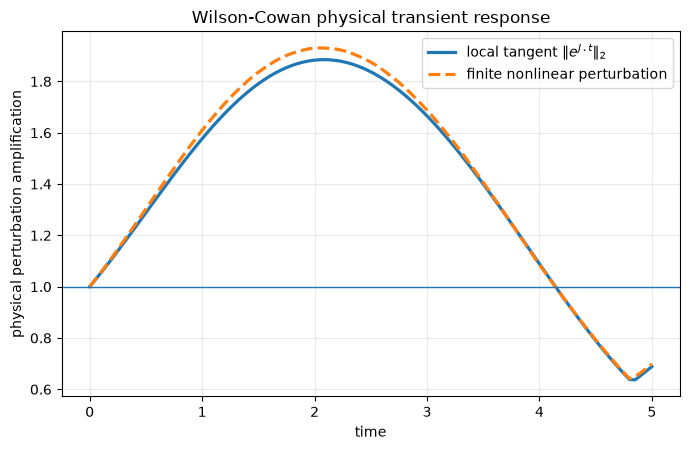

In [7]:

fig, ax = plt.subplots(figsize=(7.0, 4.6))

ax.plot(
    times,
    gain_local,
    linewidth=2.3,
    label=r"local tangent $\|e^{J_\star t}\|_2$",
)

ax.plot(
    times,
    gain_nonlinear,
    linewidth=2.3,
    linestyle="--",
    label="finite nonlinear perturbation",
)

ax.axhline(1.0, linewidth=1.0)

ax.set_xlabel("time")
ax.set_ylabel("physical perturbation amplification")
ax.set_title("Wilson-Cowan physical transient response")
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(OUTDIR, "WC_physical_transient.png"),
    dpi=400,
    bbox_inches="tight",
)

plt.show()



## 3. One-step training snapshots around the equilibrium

To avoid building the KEDMD surrogate from a single trajectory that simply collapses
toward equilibrium, we sample a local neighborhood of the stable E–I state:

\[
x_i=x_\star+\delta_i,
\qquad
\delta_i\sim[-R,R]^2,
\]

and integrate one time step,

\[
y_i=\Phi_{\Delta t}(x_i).
\]

The default radius is \(R=0.10\). The sampled states are clipped only to keep the
normalized activity variables inside \((0,1)\).


In [8]:

rng = np.random.default_rng(SEED)

X = (
    x_eq[None, :]
    + rng.uniform(
        -TRAIN_RADIUS,
        TRAIN_RADIUS,
        size=(M, 2),
    )
)

X = np.clip(X, 5e-3, 0.995)

Y = flow_batch(
    X,
    delta_t=DT,
    n_substeps=N_SUBSTEPS,
)

print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("E range in X:", X[:, 0].min(), X[:, 0].max())
print("I range in X:", X[:, 1].min(), X[:, 1].max())

print("\nFirst 3 snapshot pairs:")
for i in range(3):
    print("x =", X[i], " -> y =", Y[i])


X shape: (80, 2)
Y shape: (80, 2)
E range in X: 0.12690112154225258 0.31649831179446114
I range in X: 0.1468563395464384 0.3405083559235885

First 3 snapshot pairs:
x = [0.27715 0.23316]  -> y = [0.279334 0.235465]
x = [0.294078 0.284857]  -> y = [0.293382 0.285852]
x = [0.141194 0.340508]  -> y = [0.13745  0.335706]



## 4. Kernel definitions and median scales


In [9]:

KERNELS = ["Laplace", "Matern32", "RQ", "RBF"]


def pairwise_distance(A, B, metric="euclidean"):
    return cdist(A, B, metric=metric)


def median_scale(X, kind):
    metric = "cityblock" if kind == "Laplace" else "euclidean"

    D = pairwise_distance(
        X,
        X,
        metric=metric,
    )

    positive = D[D > 0]

    return float(np.median(positive))


def kernel_matrix(A, B, kind, gamma):

    if kind == "Laplace":
        R = pairwise_distance(
            A,
            B,
            metric="cityblock",
        )

        return np.exp(-R / gamma)

    R = pairwise_distance(
        A,
        B,
        metric="euclidean",
    )

    if kind == "Matern32":
        q = np.sqrt(3.0) * R / gamma
        return (1.0 + q) * np.exp(-q)

    if kind == "RQ":
        return (
            1.0
            + (R ** 2) / (2.0 * gamma ** 2)
        ) ** (-1.0)

    if kind == "RBF":
        return np.exp(
            -(R ** 2) / (2.0 * gamma ** 2)
        )

    raise ValueError(kind)


for kind in KERNELS:
    print(
        f"{kind:10s} gamma = "
        f"{median_scale(X, kind):.6f}"
    )


Laplace    gamma = 0.122570
Matern32   gamma = 0.097728
RQ         gamma = 0.097728
RBF        gamma = 0.097728



## 5. Original regularized KEDMD construction


In [10]:

def spd_sqrt_and_invsqrt(G, floor=1e-14):
    Gs = 0.5 * (G + G.T)

    evals, U = eigh(Gs)

    evals = np.maximum(
        evals,
        floor,
    )

    Ghalf = (
        U * np.sqrt(evals)
    ) @ U.T

    Gmhalf = (
        U * (1.0 / np.sqrt(evals))
    ) @ U.T

    return Ghalf, Gmhalf


def build_kedmd(
    X,
    Y,
    kind,
    lam=LAMBDA,
):
    gamma = median_scale(X, kind)

    GX = kernel_matrix(
        X,
        X,
        kind,
        gamma,
    )

    AX = kernel_matrix(
        Y,
        X,
        kind,
        gamma,
    )

    Glam = GX + lam * np.eye(GX.shape[0])

    A = solve(
        Glam,
        AX,
        assume_a="pos",
    )

    Ghalf, Gmhalf = spd_sqrt_and_invsqrt(Glam)

    Atilde_from_similarity = (
        Ghalf @ A @ Gmhalf
    )

    Atilde = (
        Gmhalf @ AX @ Gmhalf
    )

    rel_identity_error = (
        np.linalg.norm(
            Atilde - Atilde_from_similarity,
            ord="fro",
        )
        / np.linalg.norm(Atilde, ord="fro")
    )

    return {
        "kind": kind,
        "gamma": gamma,
        "GX": GX,
        "AX": AX,
        "Glam": Glam,
        "A": A,
        "Ghalf": Ghalf,
        "Gmhalf": Gmhalf,
        "Atilde": Atilde,
        "identity_error": rel_identity_error,
    }


models = {
    kind: build_kedmd(
        X,
        Y,
        kind,
        lam=LAMBDA,
    )
    for kind in KERNELS
}


for kind in KERNELS:
    m = models[kind]

    print(
        f"{kind:10s} | "
        f"gamma={m['gamma']:.6f} | "
        f"identity err={m['identity_error']:.3e}"
    )


Laplace    | gamma=0.122570 | identity err=2.003e-14
Matern32   | gamma=0.097728 | identity err=5.771e-13
RQ         | gamma=0.097728 | identity err=3.918e-12
RBF        | gamma=0.097728 | identity err=5.740e-12



## 6. Kernel Koopman transient amplification

For each kernel,

\[
T_k(n)
=
\|A_\lambda^n\|_{G_\lambda}
=
\|\widetilde A_\lambda^n\|_2.
\]

We also track the same fixed worst-case direction chosen at the peak time.


In [11]:

def transient_diagnostics(
    Atilde,
    T=T_TRANSIENT,
):
    d = Atilde.shape[0]

    env = np.zeros(T + 1)
    env[0] = 1.0

    powers = [np.eye(d)]

    Pmat = np.eye(d)

    for n in range(1, T + 1):

        Pmat = Pmat @ Atilde

        powers.append(Pmat.copy())

        env[n] = svdvals(Pmat)[0]

    t_peak = int(
        np.argmax(env[1:]) + 1
    )

    peak = float(env[t_peak])

    _, _, Vh = np.linalg.svd(
        powers[t_peak],
        full_matrices=False,
    )

    y_star = Vh[0, :]
    y_star = y_star / np.linalg.norm(y_star)

    fixed = np.zeros(T + 1)
    fixed[0] = 1.0

    for n in range(1, T + 1):

        fixed[n] = np.linalg.norm(
            powers[n] @ y_star
        )

    rho = float(
        np.max(
            np.abs(
                np.linalg.eigvals(Atilde)
            )
        )
    )

    dep_normal = float(
        np.linalg.norm(
            Atilde.conj().T @ Atilde
            - Atilde @ Atilde.conj().T,
            ord="fro",
        )
    )

    return {
        "env": env,
        "fixed": fixed,
        "t_peak": t_peak,
        "peak": peak,
        "rho": rho,
        "departure_normality": dep_normal,
    }


for kind in KERNELS:

    models[kind]["transient"] = transient_diagnostics(
        models[kind]["Atilde"],
        T=T_TRANSIENT,
    )


In [12]:

rows = []

for kind in KERNELS:

    m = models[kind]
    td = m["transient"]

    rows.append({
        "kernel": kind,
        "gamma": m["gamma"],
        "cond_Glambda": np.linalg.cond(m["Glam"]),
        "rho_Atilde": td["rho"],
        "departure_normality": td["departure_normality"],
        "peak_G": td["peak"],
        "t_peak": td["t_peak"],
    })

transient_table = pd.DataFrame(rows)

display(transient_table)

transient_table.to_csv(
    os.path.join(
        OUTDIR,
        "WC_transient_summary.csv",
    ),
    index=False,
)


,kernel,gamma,cond_Glambda,rho_Atilde,departure_normality,peak_G,t_peak
0,Laplace,0.122570,1621.850424,0.999922,1.728228,1.678947,27
1,Matern32,0.097728,93870.463134,0.999999,0.631684,2.859809,35
2,RQ,0.097728,181278.849340,0.999971,0.351556,3.708127,32
3,RBF,0.097728,163566.473781,1.000050,0.312017,4.709661,31


In [27]:
#plt.style.use("bmh")
plt.style.use("default")

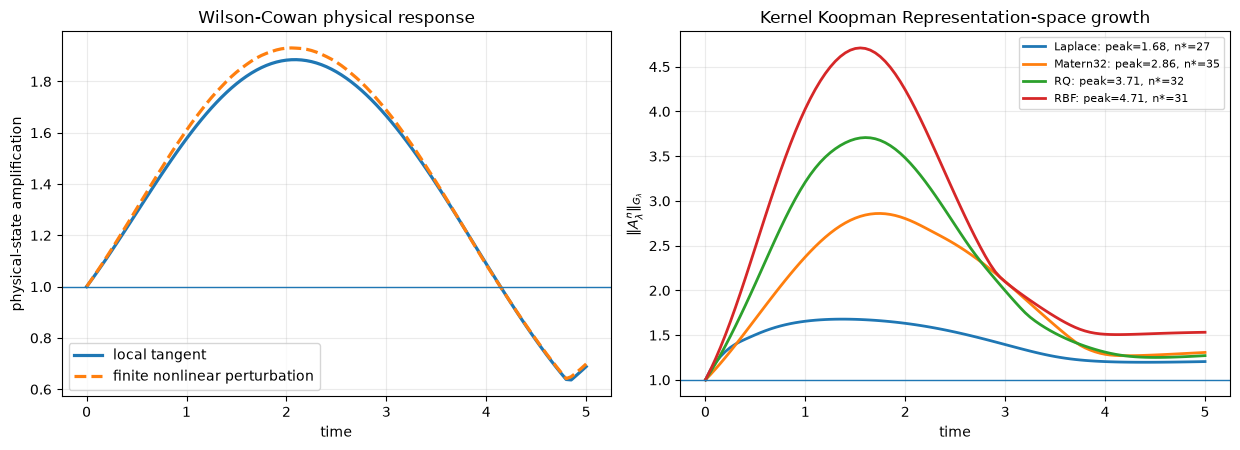

In [29]:

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.5, 4.6),
)

# ------------------------------------------------------------
# Physical nonlinear/local transient
# ------------------------------------------------------------
axes[0].plot(
    times,
    gain_local,
    linewidth=2.3,
    label="local tangent",
)

axes[0].plot(
    times,
    gain_nonlinear,
    linewidth=2.3,
    linestyle="--",
    label="finite nonlinear perturbation",
)

axes[0].axhline(1.0, linewidth=1.0)

axes[0].set_xlabel("time")
axes[0].set_ylabel("physical-state amplification")
axes[0].set_title("Wilson-Cowan physical response")
axes[0].grid(alpha=0.25)
axes[0].legend()

# ------------------------------------------------------------
# KEDMD representation-space transient
# ------------------------------------------------------------
for kind in KERNELS:

    td = models[kind]["transient"]

    axes[1].plot(
        times,
        td["env"],
        linewidth=2.0,
        label=(
            f"{kind}: "
            f"peak={td['peak']:.2f}, "
            f"n*={td['t_peak']}"
        ),
    )

axes[1].axhline(1.0, linewidth=1.0)

axes[1].set_xlabel("time")
axes[1].set_ylabel(
    r"$\|A_\lambda^n\|_{G_\lambda}$"
)

axes[1].set_title(
    "Kernel Koopman Representation-space growth"
)

axes[1].grid(alpha=0.25)
axes[1].legend(fontsize=8)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTDIR,
        "WC_physical_vs_KEDMD_transient.pdf",
    ),
    dpi=500,
    bbox_inches="tight",
)

plt.show()


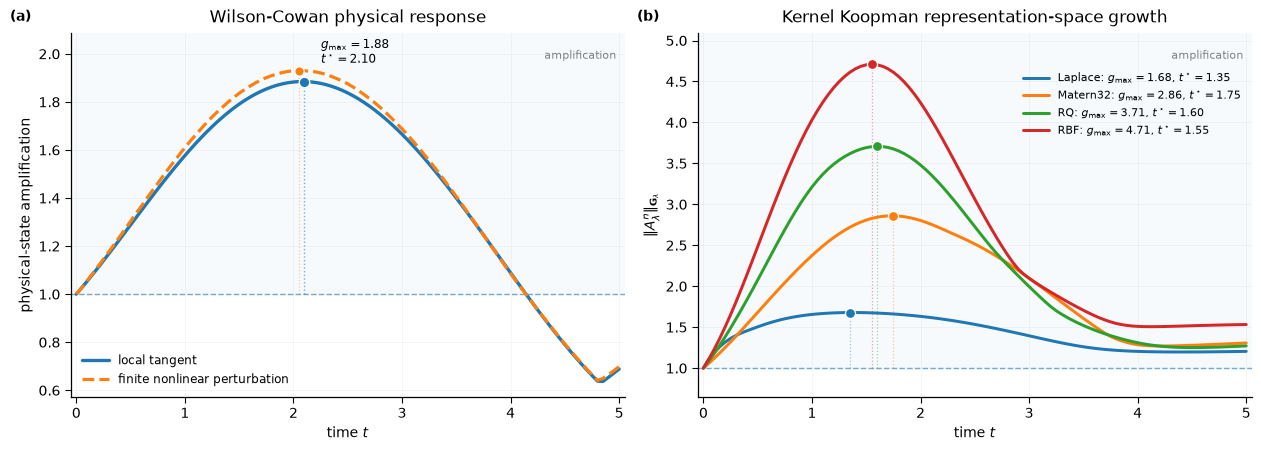

In [30]:
# Convert discrete Koopman steps to physical time
times = steps * DT

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.5, 4.4),
    constrained_layout=True
)


# ============================================================
# Common visual treatment
# ============================================================

def clean_axis(ax):

    # Do NOT touch font settings
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_linewidth(0.9)
    ax.spines["bottom"].set_linewidth(0.9)

    ax.tick_params(
        direction="out",
        length=4,
        width=0.8
    )

    ax.grid(
        True,
        linewidth=0.55,
        alpha=0.15
    )

    ax.set_axisbelow(True)


# ============================================================
# LEFT: Wilson-Cowan physical response
# ============================================================

ax = axes[0]


# ------------------------------------------------------------
# Determine physical-response extrema
# ------------------------------------------------------------

i_local = int(np.argmax(gain_local))
i_nonlinear = int(np.argmax(gain_nonlinear))

t_local_star = times[i_local]
g_local_star = gain_local[i_local]

t_nonlinear_star = times[i_nonlinear]
g_nonlinear_star = gain_nonlinear[i_nonlinear]


# ------------------------------------------------------------
# Plot range
# ------------------------------------------------------------

physical_peak = max(
    np.max(gain_local),
    np.max(gain_nonlinear)
)

physical_min = min(
    np.min(gain_local),
    np.min(gain_nonlinear)
)

y_top_left = physical_peak * 1.08

# Keep lower limit close to the actual response
y_bottom_left = max(
    0.0,
    physical_min * 0.90
)


# ------------------------------------------------------------
# Amplification region: gain > 1
# ------------------------------------------------------------

ax.axhspan(
    1.0,
    y_top_left,
    alpha=0.035,
    zorder=0
)

# Neutral gain boundary
ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.05,
    alpha=0.60,
    zorder=1
)


# ------------------------------------------------------------
# Local tangent response
# ------------------------------------------------------------

line_local, = ax.plot(
    times,
    gain_local,
    linewidth=2.4,
    solid_capstyle="round",
    label="local tangent",
    zorder=3
)


# ------------------------------------------------------------
# Finite nonlinear perturbation
# ------------------------------------------------------------

line_nonlinear, = ax.plot(
    times,
    gain_nonlinear,
    linewidth=2.3,
    linestyle="--",
    solid_capstyle="round",
    label="finite nonlinear perturbation",
    zorder=3
)


# ------------------------------------------------------------
# Peak geometry: local tangent
# ------------------------------------------------------------

ax.vlines(
    t_local_star,
    1.0,
    g_local_star,
    color=line_local.get_color(),
    linestyle=":",
    linewidth=1.0,
    alpha=0.58,
    zorder=2
)

ax.scatter(
    t_local_star,
    g_local_star,
    s=58,
    facecolor=line_local.get_color(),
    edgecolor="white",
    linewidth=1.0,
    zorder=5
)


# Main physical peak annotation
ax.annotate(
    rf"$g_{{\max}}={g_local_star:.2f}$"
    "\n"
    rf"$t^\star={t_local_star:.2f}$",
    xy=(t_local_star, g_local_star),
    xytext=(12, 10),
    textcoords="offset points",
    fontsize=8.5,
    va="bottom",
    ha="left"
)


# ------------------------------------------------------------
# Peak geometry: nonlinear perturbation
# ------------------------------------------------------------

# Mark it, but do not add another text annotation
# so that the panel remains visually clean.

ax.vlines(
    t_nonlinear_star,
    1.0,
    g_nonlinear_star,
    color=line_nonlinear.get_color(),
    linestyle=":",
    linewidth=0.9,
    alpha=0.40,
    zorder=2
)

ax.scatter(
    t_nonlinear_star,
    g_nonlinear_star,
    s=46,
    facecolor=line_nonlinear.get_color(),
    edgecolor="white",
    linewidth=0.9,
    zorder=5
)


# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_ylim(
    bottom=y_bottom_left,
    top=y_top_left
)

ax.set_xlabel("time $t$")
ax.set_ylabel("physical-state amplification")

ax.set_title(
    "Wilson-Cowan physical response",
    pad=8
)

ax.legend(
    loc="lower left",
    frameon=False,
    fontsize=8.5,
    handlelength=2.3
)

# Semantic label for region above unity
ax.text(
    0.985,
    0.955,
    "amplification",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8,
    alpha=0.48
)

clean_axis(ax)


# ============================================================
# RIGHT: KEDMD representation-space response
# ============================================================

ax = axes[1]


# ------------------------------------------------------------
# Determine vertical range
# ------------------------------------------------------------

global_peak = max(
    models[kind]["transient"]["peak"]
    for kind in KERNELS
)

y_top_right = global_peak * 1.08


# ------------------------------------------------------------
# Amplification region
# ------------------------------------------------------------

ax.axhspan(
    1.0,
    y_top_right,
    alpha=0.035,
    zorder=0
)

ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1.05,
    alpha=0.60,
    zorder=1
)


# ------------------------------------------------------------
# Kernel curves + peak geometry
# ------------------------------------------------------------

for kind in KERNELS:

    td = models[kind]["transient"]

    peak_idx = int(td["t_peak"])

    t_star = times[peak_idx]
    g_star = td["env"][peak_idx]

    line, = ax.plot(
        times,
        td["env"],
        linewidth=2.15,
        solid_capstyle="round",
        label=(
            f"{kind}: "
            rf"$g_{{\max}}={g_star:.2f}$, "
            rf"$t^\star={t_star:.2f}$"
        ),
        zorder=3
    )

    kernel_color = line.get_color()

    # Vertical stem = peak time
    ax.vlines(
        t_star,
        1.0,
        g_star,
        color=kernel_color,
        linestyle=":",
        linewidth=0.9,
        alpha=0.42,
        zorder=2
    )

    # Peak marker = peak gain
    ax.scatter(
        t_star,
        g_star,
        s=52,
        facecolor=kernel_color,
        edgecolor="white",
        linewidth=0.9,
        zorder=5
    )


# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_ylim(
    bottom=0.65,
    top=y_top_right
)

ax.set_xlabel("time $t$")

ax.set_ylabel(
    r"$\|A_\lambda^n\|_{\mathbf{G}_\lambda}$"
)

ax.set_title(
    "Kernel Koopman representation-space growth",
    pad=8
)


# Keep legend below amplification label
ax.legend(
    loc="upper right",
    bbox_to_anchor=(1.00, 0.92),
    frameon=False,
    fontsize=8.0,
    handlelength=2.3,
    labelspacing=0.50
)

ax.text(
    0.985,
    0.955,
    "amplification",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=8,
    alpha=0.48
)

clean_axis(ax)


# ============================================================
# Panel labels
# ============================================================

axes[0].text(
    -0.11,
    1.035,
    "(a)",
    transform=axes[0].transAxes,
    fontsize=10,
    fontweight="bold",
    ha="left"
)

axes[1].text(
    -0.11,
    1.035,
    "(b)",
    transform=axes[1].transAxes,
    fontsize=10,
    fontweight="bold",
    ha="left"
)


# ============================================================
# Small horizontal margins
# ============================================================

for ax in axes:
    ax.margins(x=0.01)


# ============================================================
# Save
# ============================================================

plt.savefig(
    os.path.join(
        OUTDIR,
        "WC_physical_vs_KEDMD_transient_polished.pdf"
    ),
    dpi=500,
    bbox_inches="tight"
)

plt.savefig(
    os.path.join(
        OUTDIR,
        "WC_physical_vs_KEDMD_transient_polished.png"
    ),
    dpi=500,
    bbox_inches="tight"
)

plt.show()

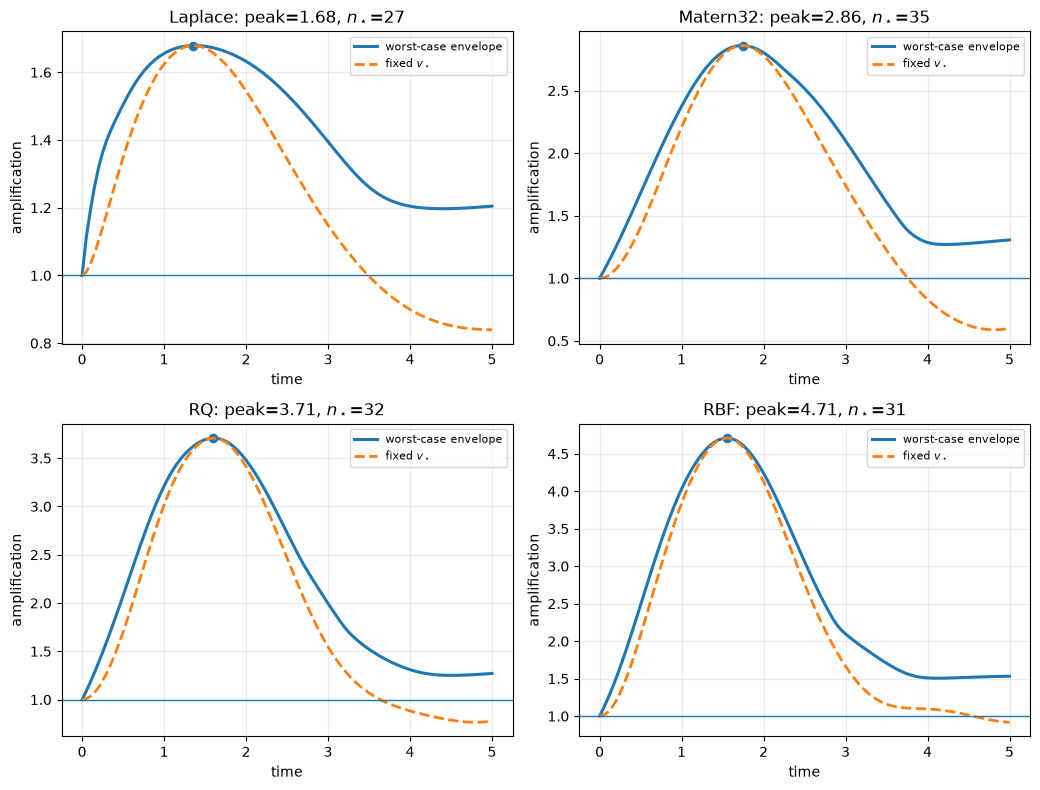

In [14]:

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10.5, 8.0),
)

axes = axes.ravel()

for ax, kind in zip(axes, KERNELS):

    td = models[kind]["transient"]

    ax.plot(
        times,
        td["env"],
        linewidth=2.2,
        label="worst-case envelope",
    )

    ax.plot(
        times,
        td["fixed"],
        linewidth=2.0,
        linestyle="--",
        label=r"fixed $v_\star$",
    )

    ax.axhline(1.0, linewidth=1.0)

    ax.scatter(
        [times[td["t_peak"]]],
        [td["peak"]],
        s=35,
    )

    ax.set_title(
        f"{kind}: peak={td['peak']:.2f}, "
        f"$n_\\star$={td['t_peak']}"
    )

    ax.set_xlabel("time")
    ax.set_ylabel("amplification")

    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTDIR,
        "WC_fixed_direction_growth.png",
    ),
    dpi=400,
    bbox_inches="tight",
)

plt.show()



## 7. Koopman surrogate pseudospectra

For the normalized surrogate,

\[
\sigma_\varepsilon(\widetilde A_\lambda)
=
\left\{
z:
\|(zI-\widetilde A_\lambda)^{-1}\|_2
>
\varepsilon^{-1}
\right\}.
\]

The resolvent norm is evaluated through the smallest singular value,

\[
\|(zI-\widetilde A_\lambda)^{-1}\|_2
=
\frac{1}{
\sigma_{\min}(zI-\widetilde A_\lambda)
}.
\]

The same grid gives the discrete Kreiss estimate

\[
\widehat{\mathcal K}
=
\max_{|z|>1}
(|z|-1)
\|(zI-\widetilde A_\lambda)^{-1}\|_2.
\]

The plotting code clips only the **displayed color values**, not the underlying
pseudospectral calculation. This avoids the artificial white holes that can appear
when `contourf` values exceed the chosen color range.


In [15]:

def resolvent_grid(
    Atilde,
    grid_lim=GRID_LIM,
    grid_n=GRID_N,
    eps_levels=EPS_LEVELS,
):
    xs = np.linspace(
        -grid_lim,
        grid_lim,
        grid_n,
    )

    ys = np.linspace(
        -grid_lim,
        grid_lim,
        grid_n,
    )

    R = np.empty(
        (grid_n, grid_n),
        dtype=float,
    )

    d = Atilde.shape[0]
    Iden = np.eye(d)

    kreiss_hat = 0.0
    kreiss_location = np.nan + 1j * np.nan

    for iy, yy in enumerate(ys):

        for ix, xx in enumerate(xs):

            z = xx + 1j * yy

            smin = svdvals(
                z * Iden - Atilde
            )[-1]

            resolvent = (
                1.0
                / max(float(smin), 1e-14)
            )

            R[iy, ix] = resolvent

            modulus = abs(z)

            if modulus > 1.0:

                value = (
                    (modulus - 1.0)
                    * resolvent
                )

                if value > kreiss_hat:

                    kreiss_hat = value
                    kreiss_location = z

    XX, YY = np.meshgrid(xs, ys)

    MOD = np.sqrt(
        XX ** 2 + YY ** 2
    )

    boundary = np.zeros_like(
        R,
        dtype=bool,
    )

    boundary[0, :] = True
    boundary[-1, :] = True
    boundary[:, 0] = True
    boundary[:, -1] = True

    radii = {}
    boundary_warning = {}

    for eps in eps_levels:

        mask = R > (1.0 / eps)

        if np.any(mask):

            radii[eps] = float(
                np.max(MOD[mask])
            )

            boundary_warning[eps] = bool(
                np.any(mask & boundary)
            )

        else:
            radii[eps] = np.nan
            boundary_warning[eps] = False

    return {
        "xs": xs,
        "ys": ys,
        "R": R,
        "log10_R": np.log10(
            np.maximum(R, 1e-14)
        ),
        "kreiss_hat": float(kreiss_hat),
        "kreiss_location": kreiss_location,
        "radii": radii,
        "boundary_warning": boundary_warning,
    }


In [16]:

t0 = time.time()

for kind in KERNELS:

    print(
        f"Computing pseudospectrum for {kind} ..."
    )

    models[kind]["pseudo"] = resolvent_grid(
        models[kind]["Atilde"],
        grid_lim=GRID_LIM,
        grid_n=GRID_N,
        eps_levels=EPS_LEVELS,
    )

print(
    "\nTotal pseudospectral runtime:",
    f"{time.time() - t0:.2f} s",
)


Computing pseudospectrum for Laplace ...
Computing pseudospectrum for Matern32 ...
Computing pseudospectrum for RQ ...
Computing pseudospectrum for RBF ...

Total pseudospectral runtime: 7.91 s


In [24]:
from matplotlib.colors import LinearSegmentedColormap

koopman_purple_luxe = LinearSegmentedColormap.from_list(
    "koopman_purple_luxe",
    [
        "#0d001a",  # black-purple
        "#240046",  # deep violet
        "#3c096c",  # royal purple
        "#5a189a",  # saturated purple
        "#7b2cbf",  # violet
        "#3a86ff",  # electric blue
        "#00b4d8",  # cyan
        "#72efdd",  # aqua
        "#ffb703",  # gold
    ],
    N=256,
)

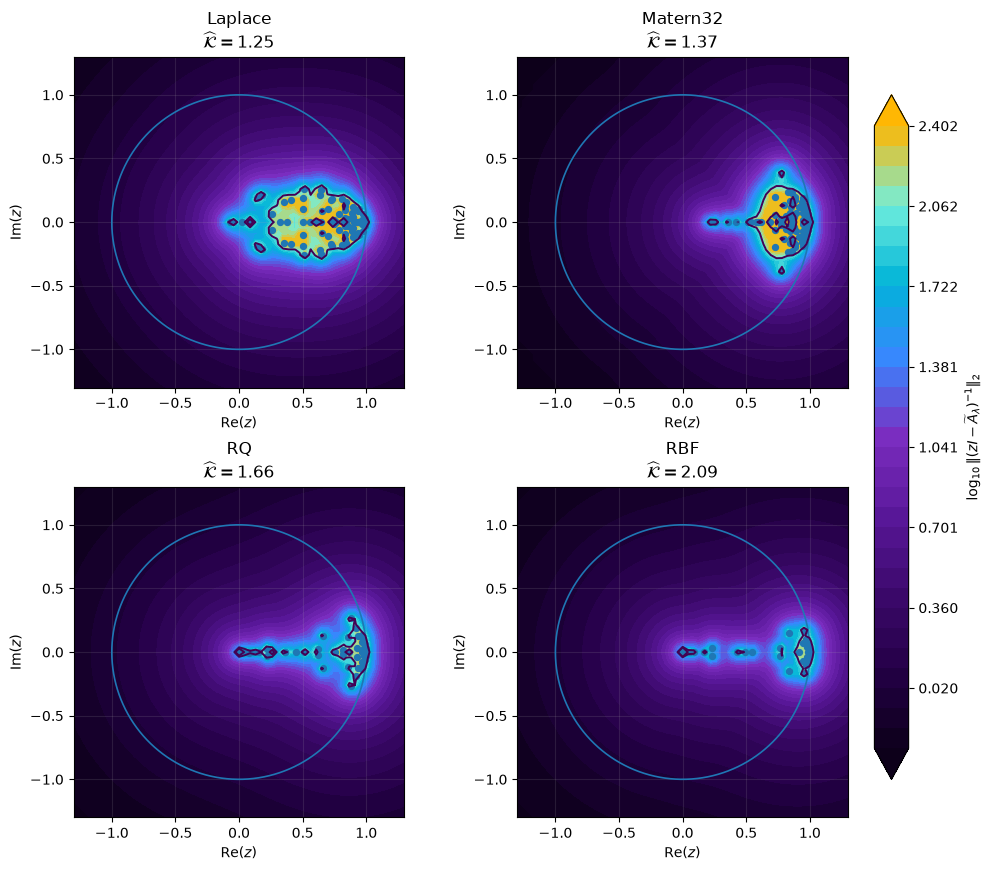

In [25]:

# ------------------------------------------------------------
# Clean common-scale pseudospectral figure
# ------------------------------------------------------------

all_logs = np.concatenate([
    models[k]["pseudo"]["log10_R"].ravel()
    for k in KERNELS
])

vmin = float(
    np.percentile(
        all_logs,
        1.0,
    )
)

vmax = float(
    np.percentile(
        all_logs,
        99.0,
    )
)

levels = np.linspace(
    vmin,
    vmax,
    32,
)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10.2, 8.6),
    constrained_layout=True,
)

axes = axes.ravel()

theta = np.linspace(
    0.0,
    2.0 * np.pi,
    600,
)

mappable = None

for ax, kind in zip(
    axes,
    KERNELS,
):

    m = models[kind]
    ps = m["pseudo"]

    XX, YY = np.meshgrid(
        ps["xs"],
        ps["ys"],
    )

    # IMPORTANT:
    # clip only for visualization.
    # The true ps["log10_R"] remains untouched.
    Zplot = np.clip(
        ps["log10_R"],
        vmin,
        vmax,
    )

    mappable = ax.contourf(
        XX,
        YY,
        Zplot,
        levels=levels,
        extend="both",
        cmap=koopman_purple_luxe
    )

    eigs = np.linalg.eigvals(
        m["Atilde"]
    )

    ax.scatter(
        np.real(eigs),
        np.imag(eigs),
        s=18,
        zorder=5,
    )

    ax.plot(
        np.cos(theta),
        np.sin(theta),
        linewidth=1.2,
        zorder=4,
    )

    for eps in EPS_LEVELS:

        threshold = np.log10(
            1.0 / eps
        )

        if (
            ps["log10_R"].min()
            <= threshold
            <= ps["log10_R"].max()
        ):

            ax.contour(
                XX,
                YY,
                ps["log10_R"],
                levels=[threshold],
                linewidths=1.4,
                zorder=6,
            )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    ax.set_xlim(
        -GRID_LIM,
        GRID_LIM,
    )

    ax.set_ylim(
        -GRID_LIM,
        GRID_LIM,
    )

    ax.set_xlabel(r"$\mathrm{Re}(z)$")
    ax.set_ylabel(r"$\mathrm{Im}(z)$")

    ax.set_title(
        f"{kind}\n"
        rf"$\widehat{{\mathcal{{K}}}}"
        rf"={ps['kreiss_hat']:.2f}$"
    )

    ax.grid(alpha=0.15)

cbar = fig.colorbar(
    mappable,
    ax=axes.tolist(),
    shrink=0.90,
    pad=0.03,
    extend="both",
)

cbar.set_label(
    r"$\log_{10}"
    r"\|(zI-\widetilde A_\lambda)^{-1}\|_2$"
)

plt.savefig(
    os.path.join(
        OUTDIR,
        "WC_KEDMD_pseudospectra_clean.pdf",
    ),
    dpi=500,
    bbox_inches="tight",
)

plt.show()


In [18]:

pseudo_rows = []

for kind in KERNELS:

    m = models[kind]
    td = m["transient"]
    ps = m["pseudo"]

    row = {
        "kernel": kind,
        "gamma": m["gamma"],
        "rho_Atilde": td["rho"],
        "peak_G": td["peak"],
        "t_peak": td["t_peak"],
        "Kreiss_hat": ps["kreiss_hat"],
    }

    for eps in EPS_LEVELS:

        row[
            f"r_eps_{eps:.0e}"
        ] = ps["radii"][eps]

        row[
            f"grid_boundary_hit_{eps:.0e}"
        ] = ps["boundary_warning"][eps]

    pseudo_rows.append(row)

pseudospectral_table = pd.DataFrame(
    pseudo_rows
)

display(pseudospectral_table)

pseudospectral_table.to_csv(
    os.path.join(
        OUTDIR,
        "WC_pseudospectral_summary.csv",
    ),
    index=False,
)


,kernel,gamma,rho_Atilde,peak_G,t_peak,Kreiss_hat,r_eps_1e-02,grid_boundary_hit_1e-02,r_eps_1e-03,grid_boundary_hit_1e-03
0,Laplace,0.122570,0.999922,1.678947,27,1.251418,0.997608,False,0.833533,False
1,Matern32,0.097728,0.999999,2.859809,35,1.371936,1.000428,False,0.953333,False
2,RQ,0.097728,0.999971,3.708127,32,1.657683,1.000428,False,0.866667,False
3,RBF,0.097728,1.000050,4.709661,31,2.090936,1.000428,False,0.000000,False



## 8. Optional local physical-state pseudospectrum

The local tangent map at the stable equilibrium is

\[
F_{\rm local}
=
e^{J_\star\Delta t}.
\]

Its \(2\times2\) pseudospectrum gives a useful physical reference.

It is **not mathematically the same object** as the KEDMD pseudospectrum because the
two operators act in different spaces.


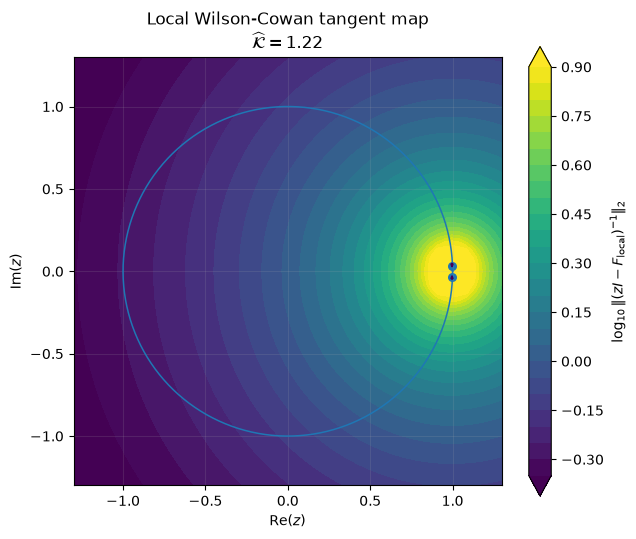

Local physical-state Kreiss estimate = 1.2208962998896362
Local physical-state pseudospectral radii = {0.01: 0.9976082508791828, 0.001: nan}


In [19]:

F_local = expm(
    J_star * DT
)

true_ps = resolvent_grid(
    F_local,
    grid_lim=GRID_LIM,
    grid_n=GRID_N,
    eps_levels=EPS_LEVELS,
)

XX, YY = np.meshgrid(
    true_ps["xs"],
    true_ps["ys"],
)

fig, ax = plt.subplots(
    figsize=(6.5, 5.5),
)

Zplot = np.clip(
    true_ps["log10_R"],
    np.percentile(
        true_ps["log10_R"],
        1.0,
    ),
    np.percentile(
        true_ps["log10_R"],
        99.0,
    ),
)

cf = ax.contourf(
    XX,
    YY,
    Zplot,
    levels=30,
    extend="both",
)

ax.scatter(
    np.real(
        np.linalg.eigvals(F_local)
    ),
    np.imag(
        np.linalg.eigvals(F_local)
    ),
    s=30,
)

ax.plot(
    np.cos(theta),
    np.sin(theta),
    linewidth=1.1,
)

for eps in EPS_LEVELS:

    threshold = np.log10(
        1.0 / eps
    )

    if (
        true_ps["log10_R"].min()
        <= threshold
        <= true_ps["log10_R"].max()
    ):

        ax.contour(
            XX,
            YY,
            true_ps["log10_R"],
            levels=[threshold],
            linewidths=1.3,
        )

ax.set_aspect(
    "equal",
    adjustable="box",
)

ax.set_xlim(
    -GRID_LIM,
    GRID_LIM,
)

ax.set_ylim(
    -GRID_LIM,
    GRID_LIM,
)

ax.set_xlabel(r"$\mathrm{Re}(z)$")
ax.set_ylabel(r"$\mathrm{Im}(z)$")

ax.set_title(
    "Local Wilson-Cowan tangent map\n"
    + rf"$\widehat{{\mathcal{{K}}}}"
    + rf"={true_ps['kreiss_hat']:.2f}$"
)

ax.grid(alpha=0.15)

fig.colorbar(
    cf,
    ax=ax,
    label=(
        r"$\log_{10}"
        r"\|(zI-F_{\rm local})^{-1}\|_2$"
    ),
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTDIR,
        "WC_local_physical_pseudospectrum.png",
    ),
    dpi=400,
    bbox_inches="tight",
)

plt.show()

print(
    "Local physical-state Kreiss estimate =",
    true_ps["kreiss_hat"],
)

print(
    "Local physical-state pseudospectral radii =",
    true_ps["radii"],
)



## 9. Regularization sensitivity

The default \(\lambda=3\times10^{-4}\) is intentionally not treated as a unique
privileged value.

The sweep below checks whether the qualitative kernel ordering survives under
reasonable regularization changes.


In [20]:

LAMBDA_SWEEP = [
    1e-2,
    3e-3,
    1e-3,
    3e-4,
    1e-4,
]

lambda_rows = []

for lam in LAMBDA_SWEEP:

    for kind in KERNELS:

        m = build_kedmd(
            X,
            Y,
            kind,
            lam=lam,
        )

        td = transient_diagnostics(
            m["Atilde"],
            T=T_TRANSIENT,
        )

        lambda_rows.append({
            "lambda": lam,
            "kernel": kind,
            "gamma": m["gamma"],
            "cond_Glambda": np.linalg.cond(
                m["Glam"]
            ),
            "rho_Atilde": td["rho"],
            "peak_G": td["peak"],
            "t_peak": td["t_peak"],
        })

lambda_table = pd.DataFrame(
    lambda_rows
)

display(lambda_table)

lambda_table.to_csv(
    os.path.join(
        OUTDIR,
        "WC_lambda_sensitivity.csv",
    ),
    index=False,
)


,lambda,kernel,gamma,cond_Glambda,rho_Atilde,peak_G,t_peak
0,0.0100,Laplace,0.122570,1100.517744,0.999571,1.398419,18
1,0.0100,Matern32,0.097728,4152.965126,1.000301,1.650734,28
2,0.0100,RQ,0.097728,5439.340368,1.000205,1.622113,27
3,0.0100,RBF,0.097728,4907.964213,1.000235,1.880831,28
4,0.0030,Laplace,0.122570,1432.873264,0.999811,1.566169,23
5,0.0030,Matern32,0.097728,13382.781427,1.000123,2.092160,31
6,0.0030,RQ,0.097728,18128.800051,1.000180,2.144005,29
7,0.0030,RBF,0.097728,16357.547378,1.000125,2.487050,29
8,0.0010,Laplace,0.122570,1568.225044,0.999890,1.643726,26
9,0.0010,Matern32,0.097728,36677.754727,1.000017,2.510859,33


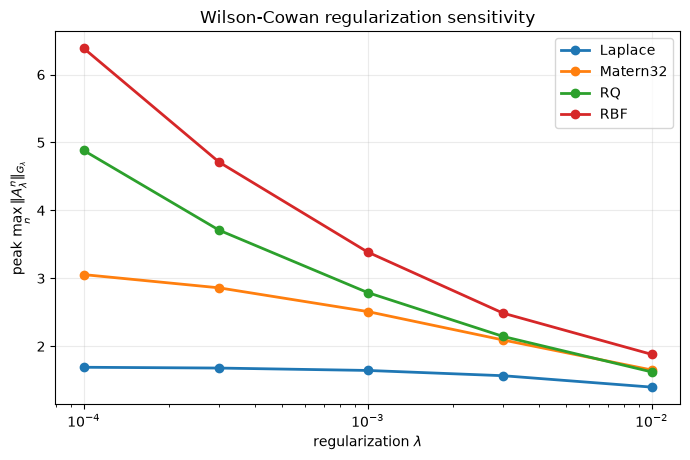

In [30]:

fig, ax = plt.subplots(
    figsize=(7.0, 4.7),
)

for kind in KERNELS:

    d = (
        lambda_table[
            lambda_table["kernel"] == kind
        ]
        .sort_values("lambda")
    )

    ax.plot(
        d["lambda"],
        d["peak_G"],
        marker="o",
        linewidth=2.0,
        label=kind,
    )

ax.set_xscale("log")

ax.set_xlabel(
    r"regularization $\lambda$"
)

ax.set_ylabel(
    r"peak "
    r"$\max_n\|A_\lambda^n\|_{G_\lambda}$"
)

ax.set_title(
    "Wilson-Cowan regularization sensitivity"
)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTDIR,
        "WC_lambda_sensitivity.pdf",
    ),
    dpi=400,
    bbox_inches="tight",
)

plt.show()



# What result are we looking for?

A useful result is **not** simply "RBF has the largest number."

The desired evidence chain is:

\[
\text{stable nonlinear E-I dynamics}
\longrightarrow
\text{kernel-dependent RKHS geometry}
\longrightarrow
\text{different non-normal surrogate behavior}
\longrightarrow
\text{different transient amplification}
\longrightarrow
\text{different pseudospectral/Kreiss inflation}.
\]

The strongest outcome would have all of the following:

1. The Wilson–Cowan equilibrium is asymptotically stable.
2. Local and finite nonlinear physical perturbations show a modest, interpretable transient.
3. Laplace, Matérn, RQ and RBF are trained from the **same** one-step snapshots.
4. Their KEDMD transient envelopes separate substantially.
5. The larger-transient kernels also have larger departure from normality.
6. Their pseudospectra broaden/inflate consistently with the transient hierarchy.
7. Their grid-based Kreiss estimates increase in the same qualitative ordering.
8. The hierarchy remains reasonably robust across the \(\lambda\) sweep.

With this experiment, the paper would no longer be demonstrating the phenomenon only
on generic benchmark dynamics. It would show the same kernel representation issue in
a nonlinear excitatory–inhibitory population model.


In [31]:
# ============================================================
# Kreiss grid-resolution convergence experiment
# ============================================================
#
# IMPORTANT:
#   - Do NOT retrain KEDMD.
#   - Do NOT modify Atilde, lambda, gamma, or the snapshots.
#   - We vary ONLY the complex-grid resolution.
#
# Run this cell after the existing models and pseudospectra
# have already been constructed.
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import svdvals


# ------------------------------------------------------------
# CHANGE THESE TWO LINES FOR EACH NOTEBOOK
# ------------------------------------------------------------

#SYSTEM_NAME = "Linear E-I"
#FILE_PREFIX = "EI"

# Wilson-Cowan:
SYSTEM_NAME = "Wilson-Cowan"
FILE_PREFIX = "WC"

# FitzHugh-Nagumo:
# SYSTEM_NAME = "FitzHugh-Nagumo"
# FILE_PREFIX = "FHN"


# ------------------------------------------------------------
# Fixed computational domain
# ------------------------------------------------------------

GRID_LIM_CONV = 1.30

# Nested grids:
# 31 -> 61 -> 121
#
# Keeping 61 is important because it is the grid used for the
# current Table-1 Kreiss values.
GRID_SIZES = [31, 61, 121]


# ============================================================
# Kreiss-only grid calculation
# ============================================================

def kreiss_grid_only(
    Atilde,
    grid_lim=1.30,
    grid_n=61,
):
    """
    Grid-based estimate of the discrete Kreiss constant

        K_hat = max_{z in G, |z| > 1}
                (|z|-1) ||(zI-Atilde)^(-1)||_2.

    This function evaluates only points outside the unit disk,
    because interior points do not enter the Kreiss objective.

    The learned Atilde is kept fixed.
    """

    xs = np.linspace(
        -grid_lim,
        grid_lim,
        grid_n,
    )

    ys = np.linspace(
        -grid_lim,
        grid_lim,
        grid_n,
    )

    d = Atilde.shape[0]

    Iden = np.eye(
        d,
        dtype=complex,
    )

    kreiss_hat = 0.0

    kreiss_location = (
        np.nan + 1j * np.nan
    )

    evaluated_points = 0

    dx = xs[1] - xs[0]
    dy = ys[1] - ys[0]

    for yy in ys:

        for xx in xs:

            z = xx + 1j * yy

            modulus = abs(z)

            # Kreiss objective only requires |z| > 1
            if modulus <= 1.0:
                continue

            evaluated_points += 1

            smin = svdvals(
                z * Iden - Atilde,
                check_finite=False,
            )[-1]

            resolvent = (
                1.0
                / max(
                    float(smin),
                    1e-14,
                )
            )

            value = (
                (modulus - 1.0)
                * resolvent
            )

            if value > kreiss_hat:

                kreiss_hat = value
                kreiss_location = z

    # --------------------------------------------------------
    # Did the maximizer land close to the OUTER box boundary?
    # --------------------------------------------------------

    boundary_tol_x = 0.51 * abs(dx)
    boundary_tol_y = 0.51 * abs(dy)

    outer_boundary_hit = bool(
        (
            abs(kreiss_location.real)
            >= grid_lim - boundary_tol_x
        )
        or
        (
            abs(kreiss_location.imag)
            >= grid_lim - boundary_tol_y
        )
    )

    return {
        "kreiss_hat": float(kreiss_hat),
        "z_star": kreiss_location,
        "abs_z_star": float(
            abs(kreiss_location)
        ),
        "grid_spacing_x": float(dx),
        "grid_spacing_y": float(dy),
        "evaluated_points": int(
            evaluated_points
        ),
        "outer_boundary_hit": (
            outer_boundary_hit
        ),
    }


# ============================================================
# Run grid convergence
# ============================================================

rows = []

total_start = time.time()


for kind in KERNELS:

    Atilde_fixed = models[kind]["Atilde"]

    print("\n" + "=" * 70)
    print(
        f"{SYSTEM_NAME} | {kind}"
    )
    print("=" * 70)

    previous_K = None

    for grid_n in GRID_SIZES:

        start = time.time()

        result = kreiss_grid_only(
            Atilde_fixed,
            grid_lim=GRID_LIM_CONV,
            grid_n=grid_n,
        )

        runtime = (
            time.time() - start
        )

        Khat = result["kreiss_hat"]

        if previous_K is None:

            relative_change = np.nan

        else:

            relative_change = (
                abs(Khat - previous_K)
                / max(abs(Khat), 1e-14)
            )

        rows.append({
            "system": SYSTEM_NAME,
            "kernel": kind,
            "grid_n": grid_n,
            "grid_points_total": (
                grid_n * grid_n
            ),
            "evaluated_exterior_points":
                result[
                    "evaluated_points"
                ],
            "grid_lim": GRID_LIM_CONV,
            "grid_spacing":
                result[
                    "grid_spacing_x"
                ],
            "kreiss_hat": Khat,
            "z_star_real":
                result["z_star"].real,
            "z_star_imag":
                result["z_star"].imag,
            "abs_z_star":
                result["abs_z_star"],
            "outer_boundary_hit":
                result[
                    "outer_boundary_hit"
                ],
            "relative_change_from_previous":
                relative_change,
            "runtime_seconds":
                runtime,
        })

        print(
            f"grid={grid_n:3d} x {grid_n:3d} | "
            f"Khat={Khat:.8f} | "
            f"z*={result['z_star']:.5f} | "
            f"|z*|={result['abs_z_star']:.6f} | "
            f"boundary={result['outer_boundary_hit']} | "
            f"time={runtime:.2f} s"
        )

        previous_K = Khat


total_runtime = (
    time.time() - total_start
)

print(
    "\nTotal grid-convergence runtime = "
    f"{total_runtime:.2f} s"
)


# ============================================================
# Save complete results
# ============================================================

kreiss_conv = pd.DataFrame(rows)

csv_path = os.path.join(
    OUTDIR,
    f"{FILE_PREFIX}_kreiss_grid_convergence.csv",
)

kreiss_conv.to_csv(
    csv_path,
    index=False,
)

print(
    "\nSaved:",
    csv_path,
)

display(kreiss_conv)


Wilson-Cowan | Laplace
grid= 31 x  31 | Khat=1.25141838 | z*=1.04000+0.00000j | |z*|=1.040000 | boundary=False | time=0.29 s
grid= 61 x  61 | Khat=1.25141838 | z*=1.04000+0.00000j | |z*|=1.040000 | boundary=False | time=1.06 s
grid=121 x 121 | Khat=1.26213500 | z*=1.06167+0.00000j | |z*|=1.061667 | boundary=False | time=4.05 s

Wilson-Cowan | Matern32
grid= 31 x  31 | Khat=1.35940561 | z*=1.04000+0.00000j | |z*|=1.040000 | boundary=False | time=0.28 s
grid= 61 x  61 | Khat=1.37193574 | z*=1.04000-0.04333j | |z*|=1.040902 | boundary=False | time=1.08 s
grid=121 x 121 | Khat=1.37810128 | z*=1.06167-0.04333j | |z*|=1.062551 | boundary=False | time=4.21 s

Wilson-Cowan | RQ
grid= 31 x  31 | Khat=1.64560670 | z*=1.04000-0.08667j | |z*|=1.043605 | boundary=False | time=0.28 s
grid= 61 x  61 | Khat=1.65768262 | z*=1.04000-0.04333j | |z*|=1.040902 | boundary=False | time=1.07 s
grid=121 x 121 | Khat=1.66176335 | z*=1.04000-0.06500j | |z*|=1.042029 | boundary=False | time=4.14 s

Wilson-Cowan 

,system,kernel,grid_n,grid_points_total,evaluated_exterior_points,grid_lim,grid_spacing,kreiss_hat,z_star_real,z_star_imag,abs_z_star,outer_boundary_hit,relative_change_from_previous,runtime_seconds
0,Wilson-Cowan,Laplace,31,961,540,1.3,0.086667,1.251418,1.040000,0.000000,1.040000,False,NaN,0.288759
1,Wilson-Cowan,Laplace,61,3721,2052,1.3,0.043333,1.251418,1.040000,0.000000,1.040000,False,0.000000,1.061501
2,Wilson-Cowan,Laplace,121,14641,7936,1.3,0.021667,1.262135,1.061667,0.000000,1.061667,False,0.008491,4.054757
3,Wilson-Cowan,Matern32,31,961,540,1.3,0.086667,1.359406,1.040000,0.000000,1.040000,False,NaN,0.284406
4,Wilson-Cowan,Matern32,61,3721,2052,1.3,0.043333,1.371936,1.040000,-0.043333,1.040902,False,0.009133,1.076055
5,Wilson-Cowan,Matern32,121,14641,7936,1.3,0.021667,1.378101,1.061667,-0.043333,1.062551,False,0.004474,4.212204
6,Wilson-Cowan,RQ,31,961,540,1.3,0.086667,1.645607,1.040000,-0.086667,1.043605,False,NaN,0.281987
7,Wilson-Cowan,RQ,61,3721,2052,1.3,0.043333,1.657683,1.040000,-0.043333,1.040902,False,0.007285,1.069672
8,Wilson-Cowan,RQ,121,14641,7936,1.3,0.021667,1.661763,1.040000,-0.065000,1.042029,False,0.002456,4.143849
9,Wilson-Cowan,RBF,31,961,540,1.3,0.086667,2.001088,1.040000,0.000000,1.040000,False,NaN,0.314715


In [36]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import os
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.linalg import solve, sqrtm, svdvals, eigvals

# ============================================================
# Output
# ============================================================
OUTDIR = "wc_mechanistic_outputs"
os.makedirs(OUTDIR, exist_ok=True)

OUT_CSV = os.path.join(OUTDIR, "WC_mechanistic_sweep.csv")

# ============================================================
# Wilson–Cowan dynamics
# ============================================================
def sigmoid(x, a=1.5, theta=0.0):
    return 1.0 / (1.0 + np.exp(-a * (x - theta)))

def wc_rhs(t, z,
           wEE=10.0, wEI=12.0, wIE=10.0, wII=0.0,
           IE=0.5, II=0.0,
           tauE=1.0, tauI=2.0,
           aE=1.5, aI=1.5,
           thE=2.8, thI=4.0):
    E, I = z
    dE = (-E + sigmoid(wEE*E - wEI*I + IE, aE, thE)) / tauE
    dI = (-I + sigmoid(wIE*E - wII*I + II, aI, thI)) / tauI
    return np.array([dE, dI])

# ============================================================
# Simulate trajectory
# ============================================================
def simulate_wc(z0, T=50.0, dt=0.05):
    t_eval = np.arange(0.0, T + dt, dt)
    sol = solve_ivp(
        wc_rhs, [0.0, T], z0,
        t_eval=t_eval,
        rtol=1e-9, atol=1e-11,
        method="RK45"
    )
    return sol.t, sol.y.T

# ============================================================
# Build snapshot pairs
# ============================================================
def make_snapshot_pairs(z0=np.array([0.15, 0.10]), T=50.0, dt=0.05, burn=200):
    t, Z = simulate_wc(z0, T=T, dt=dt)
    if burn >= len(Z) - 2:
        burn = 0
    Z = Z[burn:]
    X = Z[:-1].copy()
    Y = Z[1:].copy()
    return X, Y, t[burn:]

# ============================================================
# Kernels
# ============================================================
def pairwise_l2_sq(X, Y):
    XX = np.sum(X**2, axis=1, keepdims=True)
    YY = np.sum(Y**2, axis=1, keepdims=True).T
    D2 = XX + YY - 2.0 * X @ Y.T
    return np.maximum(D2, 0.0)

def pairwise_l2(X, Y):
    return np.sqrt(pairwise_l2_sq(X, Y))

def pairwise_l1(X, Y):
    return np.sum(np.abs(X[:, None, :] - Y[None, :, :]), axis=2)

def kernel_matrix(X, Y, kind, gamma):
    if kind.lower() == "laplace":
        D = pairwise_l1(X, Y)
        return np.exp(-D / gamma)

    elif kind.lower() == "matern32":
        D = pairwise_l2(X, Y)
        s = np.sqrt(3.0) * D / gamma
        return (1.0 + s) * np.exp(-s)

    elif kind.lower() == "rq":
        D2 = pairwise_l2_sq(X, Y)
        return (1.0 + D2 / (2.0 * gamma**2))**(-1.0)

    elif kind.lower() == "rbf":
        D2 = pairwise_l2_sq(X, Y)
        return np.exp(-D2 / (2.0 * gamma**2))

    else:
        raise ValueError(f"Unknown kernel kind: {kind}")

# ============================================================
# Heuristic gamma
# ============================================================
def median_heuristic(X):
    D = pairwise_l2(X, X)
    vals = D[np.triu_indices_from(D, k=1)]
    vals = vals[np.isfinite(vals)]
    vals = vals[vals > 0]
    if len(vals) == 0:
        return 1.0
    return np.median(vals)

# ============================================================
# SPD sqrt / invsqrt
# ============================================================
def spd_sqrt_and_invsqrt(G):
    w, V = np.linalg.eigh(G)
    w = np.maximum(w, 1e-14)
    Ghalf = (V * np.sqrt(w)) @ V.T
    Gmhalf = (V * (1.0 / np.sqrt(w))) @ V.T
    return Ghalf, Gmhalf

# ============================================================
# KEDMD build
# ============================================================
def build_kedmd(X, Y, kind, gamma, lam):
    GX = kernel_matrix(X, X, kind, gamma)
    AX = kernel_matrix(Y, X, kind, gamma)

    Glam = GX + lam * np.eye(GX.shape[0])
    A = solve(Glam, AX, assume_a="pos")

    Ghalf, Gmhalf = spd_sqrt_and_invsqrt(Glam)
    Atilde = Ghalf @ A @ Gmhalf

    eigs = eigvals(Atilde)
    rho = np.max(np.abs(eigs))
    condG = np.linalg.cond(Glam)

    return {
        "GX": GX,
        "Glam": Glam,
        "A": A,
        "Atilde": Atilde,
        "rho": rho,
        "condG": condG,
    }

# ============================================================
# Observable
# ============================================================
def observable_f(z):
    # same spirit as earlier paper: scalar observable
    # use excitatory coordinate only
    return z[:, 0]

# ============================================================
# Correlation proxy / response
# ============================================================
def empirical_corr_curve(X, Y, A, kind, gamma, horizon=20):
    """
    Approximate E-observable response under learned surrogate.
    """
    n = X.shape[0]
    fX = observable_f(X)
    fX = fX - np.mean(fX)

    # decoder c from least squares in kernel basis
    GX = kernel_matrix(X, X, kind, gamma)
    c = solve(GX + 1e-8*np.eye(n), fX, assume_a="pos")

    # initial coefficient vector
    alpha = c.copy()

    vals = []
    cur = alpha.copy()
    for t in range(1, horizon + 1):
        cur = A.T @ cur
        vals.append(np.abs(np.dot(c, GX @ cur)))
    return np.array(vals)

# ============================================================
# Peak finite-time gain
# ============================================================
def transient_envelope(Atilde, T=40):
    M = np.eye(Atilde.shape[0])
    env = []
    for _ in range(T):
        M = Atilde @ M
        env.append(np.max(svdvals(M)))
    env = np.array(env)
    peak = float(np.max(env))
    t_peak = int(np.argmax(env) + 1)
    return env, peak, t_peak

# ============================================================
# Main sweep
# ============================================================
def main():
    X, Y, _ = make_snapshot_pairs()

    gamma0 = median_heuristic(X)

    kernels = ["laplace", "matern32", "rq", "rbf"]
    lambdas = [1e-7, 1e-6, 1e-5, 1e-4]

    rows = []

    for kind in kernels:
        # use the same comparable scaling as before
        if kind == "laplace":
            gamma = gamma0
        else:
            gamma = 0.8 * gamma0

        for lam in lambdas:
            m = build_kedmd(X, Y, kind, gamma, lam)
            env, peakG, tpeak = transient_envelope(m["Atilde"], T=40)
            corr = empirical_corr_curve(X, Y, m["A"], kind, gamma, horizon=12)

            rows.append({
                "system": "Wilson-Cowan",
                "kernel": kind,
                "lambda": lam,
                "gamma": gamma,
                "cond_Glambda": m["condG"],
                "rho_Atilde": m["rho"],
                "peak_G": peakG,
                "t_peak_G": tpeak,
                "corr_peak": float(np.max(corr)),
                "t_peak_corr": int(np.argmax(corr) + 1),
            })

            print(f"[done] {kind:8s} lam={lam:.0e}  cond={m['condG']:.3e}  "
                  f"rho={m['rho']:.4f}  peakG={peakG:.3f}  corr_peak={np.max(corr):.3f}")

    df = pd.DataFrame(rows)
    df.to_csv(OUT_CSV, index=False)

    print("\nSaved:")
    print(OUT_CSV)
    print(df)

if __name__ == "__main__":
    main()

[done] laplace  lam=1e-07  cond=2.849e+06  rho=1.0000  peakG=4.615  corr_peak=0.607
[done] laplace  lam=1e-06  cond=2.830e+06  rho=1.0000  peakG=4.442  corr_peak=0.607
[done] laplace  lam=1e-05  cond=2.650e+06  rho=1.0000  peakG=4.295  corr_peak=0.608
[done] laplace  lam=1e-04  cond=1.619e+06  rho=1.0000  peakG=3.997  corr_peak=0.612
[done] matern32 lam=1e-07  cond=4.217e+09  rho=1.0000  peakG=53.010  corr_peak=4802.175
[done] matern32 lam=1e-06  cond=4.281e+08  rho=1.0000  peakG=45.896  corr_peak=798.084
[done] matern32 lam=1e-05  cond=4.287e+07  rho=1.0000  peakG=34.890  corr_peak=64.242
[done] matern32 lam=1e-04  cond=4.288e+06  rho=1.0000  peakG=21.633  corr_peak=15.720
[done] rq       lam=1e-07  cond=4.996e+09  rho=1.0000  peakG=1461.340  corr_peak=94672.273
[done] rq       lam=1e-06  cond=4.996e+08  rho=1.0000  peakG=490.028  corr_peak=16668.487
[done] rq       lam=1e-05  cond=4.996e+07  rho=1.0000  peakG=164.152  corr_peak=1684.648
[done] rq       lam=1e-04  cond=4.996e+06  rho=

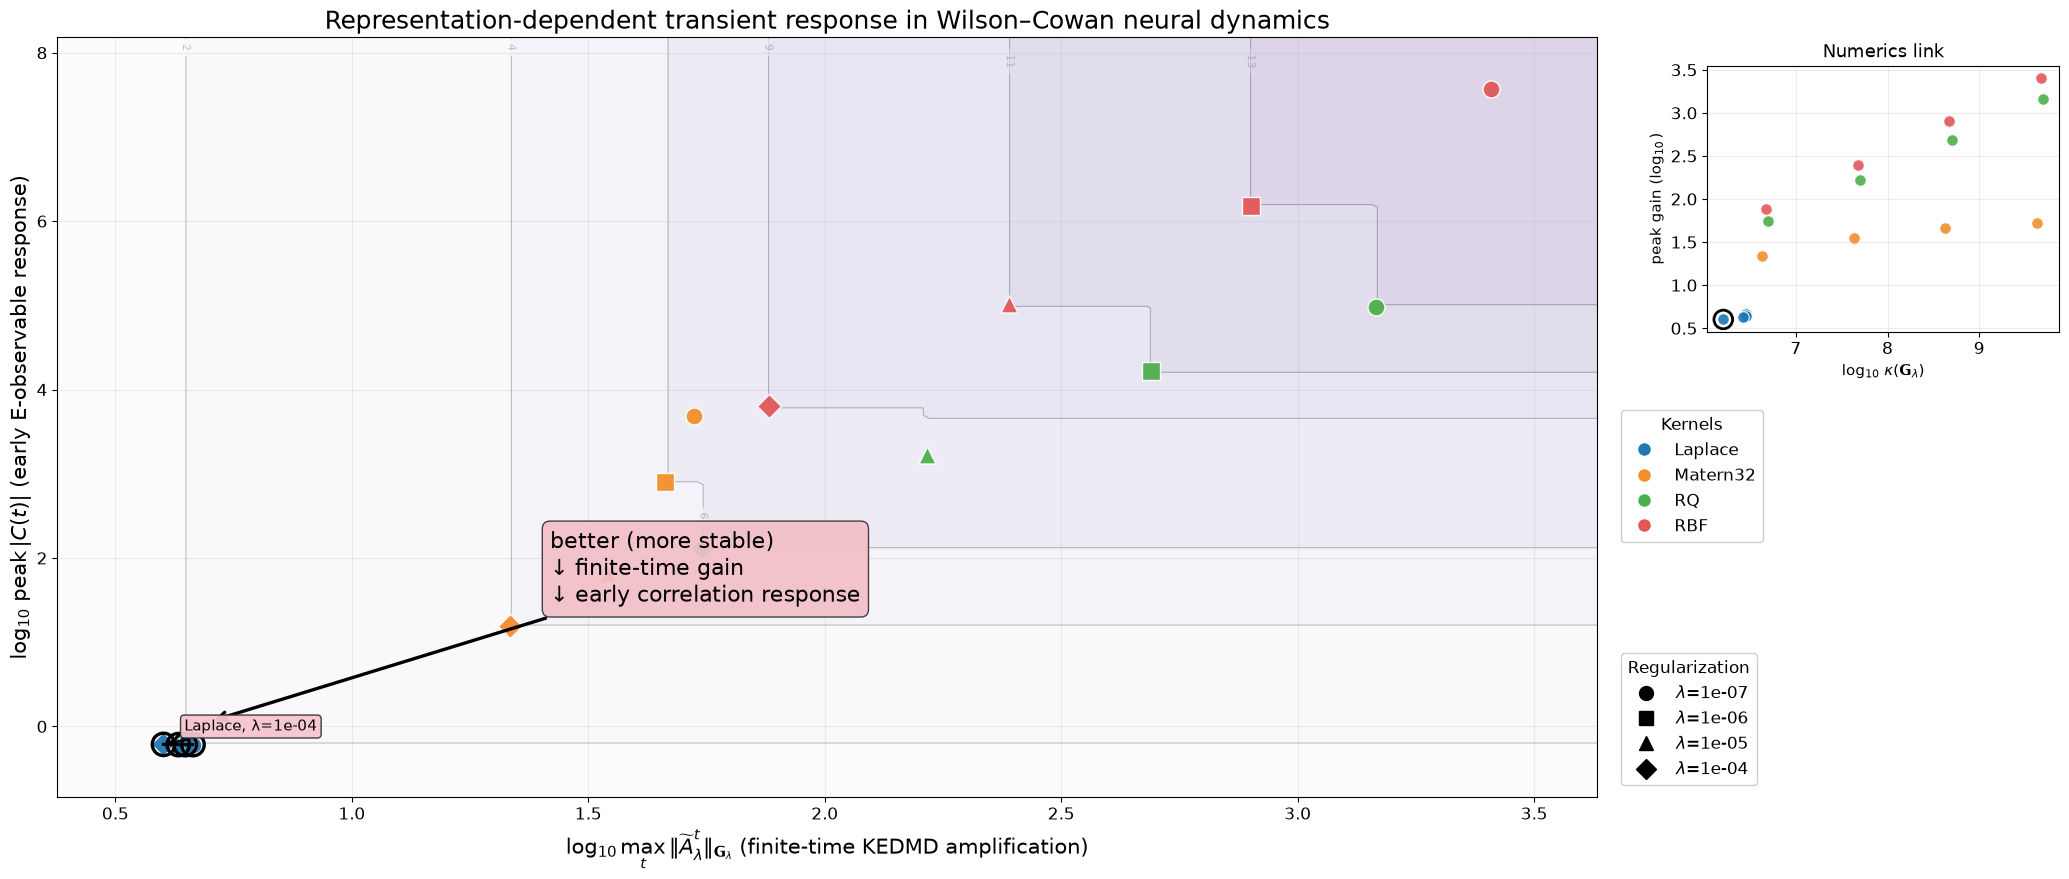

Saved: wc_mechanistic_outputs/WC_pareto_dominance_neurreps.png
Saved: wc_mechanistic_outputs/WC_pareto_dominance_neurreps.pdf


In [44]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# Paths
# ============================================================
CSV_PATH = "wc_mechanistic_outputs/WC_mechanistic_sweep.csv"
OUTDIR   = "wc_mechanistic_outputs"
os.makedirs(OUTDIR, exist_ok=True)

OUT_PNG = os.path.join(OUTDIR, "WC_pareto_dominance_neurreps.png")
OUT_PDF = os.path.join(OUTDIR, "WC_pareto_dominance_neurreps.pdf")

# ============================================================
# Pareto utilities
# ============================================================
def pareto_mask_min2(x, y):
    x = np.asarray(x)
    y = np.asarray(y)
    n = len(x)
    keep = np.ones(n, dtype=bool)
    for i in range(n):
        dominated = (x <= x[i]) & (y <= y[i]) & ((x < x[i]) | (y < y[i]))
        dominated[i] = False
        if np.any(dominated):
            keep[i] = False
    return keep

def dominance_count(xs, ys, gx, gy):
    Z = np.zeros((len(gy), len(gx)))
    for iy, yy in enumerate(gy):
        for ix, xx in enumerate(gx):
            dom = (xs <= xx) & (ys <= yy) & ((xs < xx) | (ys < yy))
            Z[iy, ix] = np.sum(dom)
    return Z

# ============================================================
# Load data
# ============================================================
df = pd.read_csv(CSV_PATH)

required = ["kernel", "lambda", "cond_Glambda", "peak_G", "corr_peak"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

# log coordinates
eps = 1e-16
df["log_peakG"]    = np.log10(np.maximum(df["peak_G"].values, eps))
df["log_corrpeak"] = np.log10(np.maximum(df["corr_peak"].values, eps))
df["log_condG"]    = np.log10(np.maximum(df["cond_Glambda"].values, eps))

# Pareto front: minimize both
mask_pf = pareto_mask_min2(df["log_peakG"], df["log_corrpeak"])
df["pareto"] = mask_pf

# ============================================================
# Style
# ============================================================
kernel_order = ["laplace", "matern32", "rq", "rbf"]
kernel_label = {
    "laplace": "Laplace",
    "matern32": "Matern32",
    "rq": "RQ",
    "rbf": "RBF",
}
kernel_color = {
    "laplace": "#1f77b4",
    "matern32": "#f28e2b",
    "rq": "#4daf4a",
    "rbf": "#e15759",
}

lam_marker = {
    1e-7: "o",
    1e-6: "s",
    1e-5: "^",
    1e-4: "D",
}

# ============================================================
# Dominance background
# ============================================================
x = df["log_peakG"].values
y = df["log_corrpeak"].values

padx = 0.08 * (x.max() - x.min() + 1e-12)
pady = 0.08 * (y.max() - y.min() + 1e-12)

gx = np.linspace(x.min() - padx, x.max() + padx, 220)
gy = np.linspace(y.min() - pady, y.max() + pady, 220)
Z  = dominance_count(x, y, gx, gy)

# ============================================================
# Plot
# ============================================================
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.labelsize": 15,
    "legend.fontsize": 12,
})

fig = plt.figure(figsize=(22, 9.5))
ax  = fig.add_axes([0.07, 0.11, 0.70, 0.80])
ax_in = fig.add_axes([0.82, 0.60, 0.16, 0.28])

# Background contour
levels = np.linspace(np.min(Z), np.max(Z), 8)
cf = ax.contourf(gx, gy, Z, levels=levels, alpha=0.18, cmap="Purples")
cs = ax.contour(gx, gy, Z, levels=levels[1:-1], colors="gray", linewidths=0.8, alpha=0.45)
ax.clabel(cs, fmt="%d", fontsize=8)

# Scatter by kernel / lambda
for k in kernel_order:
    dk = df[df["kernel"] == k]
    for lam, mk in lam_marker.items():
        dkl = dk[np.isclose(dk["lambda"], lam)]
        if len(dkl) == 0:
            continue
        ax.scatter(
            dkl["log_peakG"], dkl["log_corrpeak"],
            s=150,
            marker=mk,
            c=kernel_color[k],
            edgecolors="white",
            linewidths=1.0,
            alpha=0.95,
            zorder=4
        )

# Pareto frontier
pf = df[df["pareto"]].copy()
pf = pf.sort_values("log_peakG")
ax.plot(
    pf["log_peakG"], pf["log_corrpeak"],
    color="black", linewidth=2.3, alpha=0.95, zorder=5
)
ax.scatter(
    pf["log_peakG"], pf["log_corrpeak"],
    s=260, facecolors="none", edgecolors="black",
    linewidths=2.4, zorder=6
)

# Best point annotation
best_idx = np.argmin(df["log_peakG"].values + df["log_corrpeak"].values)
best = df.iloc[best_idx]
txt = f"{kernel_label[best['kernel']]}, λ={best['lambda']:.0e}"
ax.annotate(
    txt,
    (best["log_peakG"], best["log_corrpeak"]),
    xytext=(15, 10),
    textcoords="offset points",
    fontsize=11,
    bbox=dict(boxstyle="round,pad=0.25", fc="#f5c6cf", ec="#333333", alpha=0.95),
    arrowprops=dict(arrowstyle="->", lw=1.8, color="black"),
    zorder=10
)

# Better direction annotation
xmin, xmax = ax.get_xlim()
ymin, ymax = ax.get_ylim()
ax.annotate(
    "better (more stable)\n↓ finite-time gain\n↓ early correlation response",
    xy=(xmin + 0.10*(xmax-xmin), ymin + 0.10*(ymax-ymin)),
    xytext=(xmin + 0.32*(xmax-xmin), ymin + 0.30*(ymax-ymin)),
    fontsize=16,
    ha="left",
    va="center",
    bbox=dict(boxstyle="round,pad=0.35", fc="#f2bfc7", ec="#333333", alpha=0.92),
    arrowprops=dict(arrowstyle="->", lw=2.4, color="black"),
    zorder=8
)

ax.set_xlabel(r"$\log_{10}\max_t \Vert \widetilde{A}_\lambda^t\Vert_{\mathbf{G}_{\lambda}}$ (finite-time KEDMD amplification)")
ax.set_ylabel(r"$\log_{10}\,\mathrm{peak}\,|C(t)|$ (early E-observable response)")
ax.set_title("Representation-dependent transient response in Wilson–Cowan neural dynamics")
ax.grid(alpha=0.22)

# Inset: numerics link
for k in kernel_order:
    dk = df[df["kernel"] == k]
    ax_in.scatter(
        dk["log_condG"], dk["log_peakG"],
        s=70,
        c=kernel_color[k],
        alpha=0.9,
        edgecolors="white",
        linewidths=0.8
    )

# highlight Pareto-optimal in inset
ax_in.scatter(
    best["log_condG"], best["log_peakG"],
    s=180, facecolors="none", edgecolors="black", linewidths=2.0, zorder=6
)

ax_in.set_title("Numerics link", fontsize=13)
ax_in.set_xlabel(r"$\log_{10}\,\kappa(\mathbf{G}_\lambda)$", fontsize=11)
ax_in.set_ylabel(r"peak gain $(\log_{10})$", fontsize=11)
ax_in.grid(alpha=0.22)

# Legends
kernel_handles = [
    Line2D([0], [0], marker="o", color="none",
           markerfacecolor=kernel_color[k], markeredgecolor="white",
           markersize=10, label=kernel_label[k])
    for k in kernel_order
]

lam_handles = [
    Line2D([0], [0], marker=mk, color="black", linestyle="None",
           markersize=10, label=rf"$\lambda$={lam:.0e}")
    for lam, mk in lam_marker.items()
]

leg1 = ax.legend(
    handles=kernel_handles,
    title="Kernels",
    loc="upper left",
    bbox_to_anchor=(1.01, 0.52),
    framealpha=0.95
)
ax.add_artist(leg1)

ax.legend(
    handles=lam_handles,
    title="Regularization",
    loc="upper left",
    bbox_to_anchor=(1.01, 0.2),
    framealpha=0.95
)

plt.savefig(OUT_PNG, dpi=500, bbox_inches="tight")
plt.savefig(OUT_PDF, dpi=500, bbox_inches="tight")
plt.show()

print(f"Saved: {OUT_PNG}")
print(f"Saved: {OUT_PDF}")


Wilson-Cowan dynamical Pareto set:
 kernel       lambda   peak_G  corr_peak
Laplace 1.000000e-04 3.997139   0.611767
Laplace 1.000000e-05 4.294566   0.607803
Laplace 1.000000e-06 4.441774   0.607363
Laplace 1.000000e-07 4.615231   0.607319

Wilson-Cowan numerical Pareto set:
 kernel  lambda  cond_Glambda   peak_G
Laplace  0.0001  1.618783e+06 3.997139


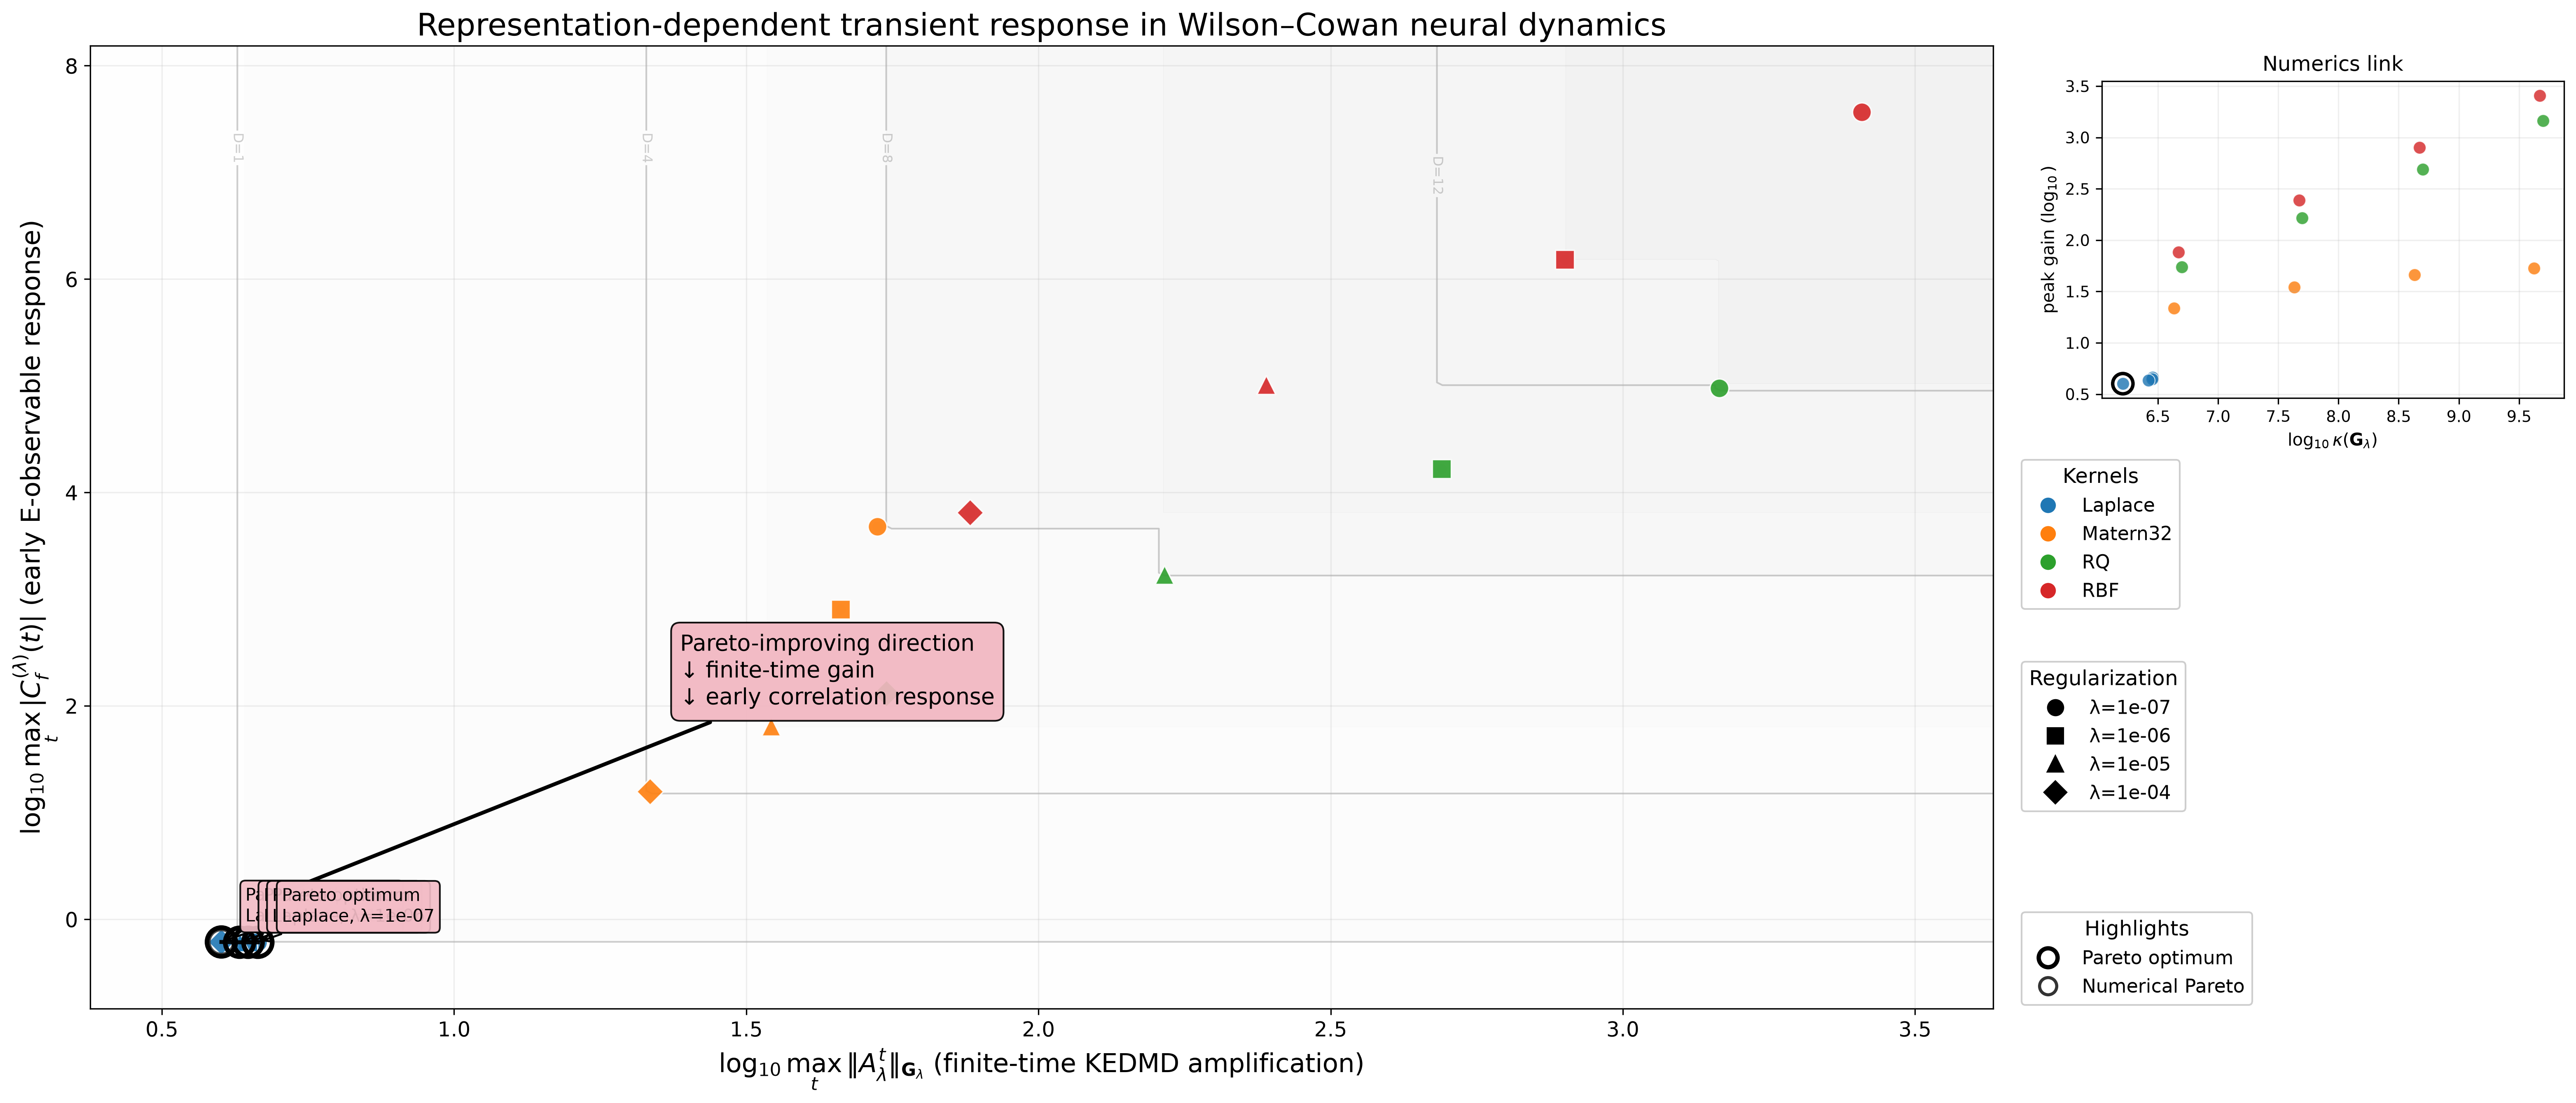


Saved:
wc_mechanistic_outputs/WC_pareto_dominance_neurreps.png
wc_mechanistic_outputs/WC_pareto_dominance_neurreps.pdf


In [52]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

# ============================================================
# WILSON-COWAN PARETO-DOMINANCE FIGURE
#
# Uniform with the stable E-I mechanistic figure.
#
# Main plane:
#
#   x = log10 peak finite-time KEDMD amplification
#   y = log10 peak early E-observable response
#
# Inset:
#
#   x = log10 cond(G_lambda)
#   y = log10 peak finite-time KEDMD amplification
#
# Dominance contours:
#
#   D(x,y) = number of sampled configurations that dominate
#            location (x,y), with both objectives minimized.
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D


# ============================================================
# 0. PATHS
# ============================================================

OUTDIR = "wc_mechanistic_outputs"

CSV_PATH = os.path.join(
    OUTDIR,
    "WC_mechanistic_sweep.csv"
)

OUT_PNG = os.path.join(
    OUTDIR,
    "WC_pareto_dominance_neurreps.png"
)

OUT_PDF = os.path.join(
    OUTDIR,
    "WC_pareto_dominance_neurreps.pdf"
)

os.makedirs(
    OUTDIR,
    exist_ok=True
)


# ============================================================
# 1. PARETO UTILITIES
# ============================================================

def pareto_mask_min2(x, y):
    """
    Return True for points that are nondominated
    when BOTH coordinates are minimized.
    """

    x = np.asarray(x)
    y = np.asarray(y)

    n = len(x)

    keep = np.ones(
        n,
        dtype=bool
    )

    for i in range(n):

        dominates_i = (
            (x <= x[i])
            &
            (y <= y[i])
            &
            (
                (x < x[i])
                |
                (y < y[i])
            )
        )

        dominates_i[i] = False

        if np.any(dominates_i):
            keep[i] = False

    return keep


def dominance_field(
    x_data,
    y_data,
    x_grid,
    y_grid
):
    """
    D(x,y) = number of sampled configurations satisfying

        x_i <= x
        y_i <= y

    Thus D increases toward the upper-right,
    i.e. toward increasingly dominated objective space.
    """

    XX, YY = np.meshgrid(
        x_grid,
        y_grid
    )

    D = np.zeros_like(
        XX,
        dtype=float
    )

    for xi, yi in zip(
        x_data,
        y_data
    ):

        D += (
            (xi <= XX)
            &
            (yi <= YY)
        )

    return XX, YY, D


# ============================================================
# 2. LOAD DATA
# ============================================================

df = pd.read_csv(
    CSV_PATH
)

required = [
    "kernel",
    "lambda",
    "cond_Glambda",
    "peak_G",
    "corr_peak",
]

missing = [
    c
    for c in required
    if c not in df.columns
]

if missing:

    raise ValueError(
        f"Missing required columns: {missing}\n"
        f"Found: {df.columns.tolist()}"
    )


# ============================================================
# 3. STANDARDIZE KERNEL NAMES
#
# Allows your WC CSV to contain lowercase names while the
# plot matches the E-I figure exactly.
# ============================================================

kernel_name_map = {

    "laplace":
        "Laplace",

    "Laplace":
        "Laplace",

    "matern32":
        "Matern32",

    "Matern32":
        "Matern32",

    "rq":
        "RQ",

    "RQ":
        "RQ",

    "rbf":
        "RBF",

    "RBF":
        "RBF",
}

df["kernel"] = (
    df["kernel"]
    .map(
        lambda x:
        kernel_name_map.get(
            x,
            x
        )
    )
)


# ============================================================
# 4. LOG OBJECTIVE COORDINATES
# ============================================================

tiny = 1e-16


df["logCond"] = np.log10(
    np.maximum(
        df["cond_Glambda"].to_numpy(),
        tiny
    )
)


df["logGain"] = np.log10(
    np.maximum(
        df["peak_G"].to_numpy(),
        tiny
    )
)


df["logCorr"] = np.log10(
    np.maximum(
        df["corr_peak"].to_numpy(),
        tiny
    )
)


# ============================================================
# 5. TWO PARETO SETS
# ============================================================

# ------------------------------------------------------------
# Dynamical Pareto:
#
# minimize
#
#   finite-time gain
#   early correlation response
# ------------------------------------------------------------

df["pareto_dyn"] = pareto_mask_min2(
    df["logGain"],
    df["logCorr"]
)


# ------------------------------------------------------------
# Numerical Pareto:
#
# minimize
#
#   cond(G_lambda)
#   finite-time gain
# ------------------------------------------------------------

df["pareto_num"] = pareto_mask_min2(
    df["logCond"],
    df["logGain"]
)


pareto_dyn = (
    df[
        df["pareto_dyn"]
    ]
    .sort_values(
        "logGain"
    )
    .copy()
)


pareto_num = (
    df[
        df["pareto_num"]
    ]
    .sort_values(
        "logCond"
    )
    .copy()
)


print(
    "\nWilson-Cowan dynamical Pareto set:"
)

print(
    pareto_dyn[
        [
            "kernel",
            "lambda",
            "peak_G",
            "corr_peak",
        ]
    ].to_string(
        index=False
    )
)


print(
    "\nWilson-Cowan numerical Pareto set:"
)

print(
    pareto_num[
        [
            "kernel",
            "lambda",
            "cond_Glambda",
            "peak_G",
        ]
    ].to_string(
        index=False
    )
)


# ============================================================
# 6. UNIFORM STYLE
# ============================================================

plt.rcParams.update({

    # No custom mathtext font
    "text.usetex":
        False,

    "font.family":
        "DejaVu Sans",

    "font.size":
        12,

    "axes.titlesize":
        18,

    "axes.labelsize":
        15,

    "xtick.labelsize":
        12,

    "ytick.labelsize":
        12,

    "legend.fontsize":
        11,

    "pdf.fonttype":
        42,

    "ps.fonttype":
        42,
})


# ============================================================
# 7. KERNEL COLORS — SAME AS E-I
# ============================================================

kernel_order = [
    "Laplace",
    "Matern32",
    "RQ",
    "RBF",
]


kernel_color = {

    "Laplace":
        "#1f77b4",

    "Matern32":
        "#ff7f0e",

    "RQ":
        "#2ca02c",

    "RBF":
        "#d62728",
}


# ============================================================
# 8. REGULARIZATION MARKERS
#
# Automatically derived from CSV so we don't hard-code a
# different regularization sweep accidentally.
# ============================================================

lambda_order = sorted(
    df["lambda"].unique()
)


marker_cycle = [
    "o",
    "s",
    "^",
    "D",
    "P",
    "X",
    "v",
    "<",
    ">",
]


lambda_marker = {

    lam:
        marker_cycle[
            i
            %
            len(marker_cycle)
        ]

    for i, lam
    in enumerate(
        lambda_order
    )
}


# ============================================================
# 9. DOMINANCE FIELD
# ============================================================

x_data = (
    df["logGain"]
    .to_numpy()
)

y_data = (
    df["logCorr"]
    .to_numpy()
)


x_span = max(
    x_data.max()
    -
    x_data.min(),
    1e-6
)


y_span = max(
    y_data.max()
    -
    y_data.min(),
    1e-6
)


x_grid = np.linspace(

    x_data.min()
    -
    0.08*x_span,

    x_data.max()
    +
    0.08*x_span,

    350
)


y_grid = np.linspace(

    y_data.min()
    -
    0.08*y_span,

    y_data.max()
    +
    0.08*y_span,

    350
)


XX, YY, D = dominance_field(
    x_data,
    y_data,
    x_grid,
    y_grid
)


# ============================================================
# 10. DOMINANCE CONTOUR LEVELS
#
# Same interpretation as E-I.
#
# Adaptive because WC may have a different number of sampled
# configurations.
# ============================================================

N = len(
    df
)


candidate_levels = [

    1,

    int(
        np.ceil(
            0.25*N
        )
    ),

    int(
        np.ceil(
            0.50*N
        )
    ),

    int(
        np.ceil(
            0.75*N
        )
    ),
]


dominance_levels = sorted(
    set(
        [
            level
            for level
            in candidate_levels
            if (
                level > 0
                and
                level < N
            )
        ]
    )
)


# ============================================================
# 11. FIGURE — SAME GEOMETRY AS E-I
# ============================================================

fig = plt.figure(
    figsize=(22.0, 9.5),
    dpi=300
)


# Main objective plane
ax = fig.add_axes(
    [
        0.07,
        0.10,
        0.70,
        0.82
    ]
)


# Numerics inset
ax_in = fig.add_axes(
    [
        0.81,
        0.62,
        0.17,
        0.27
    ]
)


# ============================================================
# 12. SUBTLE PARETO-DOMINANCE BACKGROUND
#
# IMPORTANT:
# use neutral Greys, not Purple.
# This is dominance geometry, NOT density.
# ============================================================

fill_levels = np.linspace(
    -0.5,
    N + 0.5,
    7
)


ax.contourf(

    XX,
    YY,
    D,

    levels=
        fill_levels,

    cmap=
        "Greys",

    alpha=
        0.055,

    zorder=
        0
)


# ------------------------------------------------------------
# dominance contour lines
# ------------------------------------------------------------

if len(
    dominance_levels
) > 0:

    CS = ax.contour(

        XX,
        YY,
        D,

        levels=
            dominance_levels,

        colors=
            "#7d7d7d",

        linewidths=
            1.0,

        alpha=
            0.38,

        zorder=
            1
    )


    contour_labels = {

        level:
            f"D={level}"

        for level
        in dominance_levels
    }


    ax.clabel(

        CS,

        inline=
            True,

        fontsize=
            8,

        fmt=
            contour_labels
    )


# ============================================================
# 13. FAINT DATA CLOUD
# ============================================================

ax.scatter(

    df["logGain"],
    df["logCorr"],

    s=
        35,

    color=
        "lightgray",

    alpha=
        0.25,

    linewidths=
        0,

    zorder=
        2
)


# ============================================================
# 14. KERNEL / REGULARIZATION SCATTER
# ============================================================

for kind in kernel_order:

    dk = df[
        df["kernel"]
        ==
        kind
    ]

    for lam in lambda_order:

        dkl = dk[
            np.isclose(
                dk["lambda"],
                lam
            )
        ]

        if dkl.empty:
            continue


        ax.scatter(

            dkl["logGain"],
            dkl["logCorr"],

            s=
                120,

            marker=
                lambda_marker[
                    lam
                ],

            color=
                kernel_color[
                    kind
                ],

            edgecolors=
                "white",

            linewidths=
                0.8,

            alpha=
                0.90,

            zorder=
                4
        )


# ============================================================
# 15. TRUE EMPIRICAL PARETO SET
# ============================================================

if len(
    pareto_dyn
) > 1:

    ax.plot(

        pareto_dyn[
            "logGain"
        ],

        pareto_dyn[
            "logCorr"
        ],

        color=
            "black",

        linewidth=
            2.3,

        alpha=
            0.95,

        zorder=
            6
    )


ax.scatter(

    pareto_dyn[
        "logGain"
    ],

    pareto_dyn[
        "logCorr"
    ],

    s=
        280,

    facecolors=
        "none",

    edgecolors=
        "black",

    linewidths=
        2.7,

    zorder=
        7
)


# ============================================================
# 16. NUMERICAL-PARETO RINGS
# ============================================================

ax.scatter(

    pareto_num[
        "logGain"
    ],

    pareto_num[
        "logCorr"
    ],

    s=
        205,

    facecolors=
        "none",

    edgecolors=
        "#333333",

    linewidths=
        1.8,

    alpha=
        0.90,

    zorder=
        6
)


# ============================================================
# 17. LABEL THE TRUE PARETO CONFIGURATION(S)
#
# Do NOT use minimum x+y.
# ============================================================

for _, row in pareto_dyn.iterrows():

    label = (

        "Pareto optimum\n"

        +

        f"{row['kernel']}, "
        f"λ={row['lambda']:.0e}"
    )


    ax.annotate(

        label,

        (
            row[
                "logGain"
            ],

            row[
                "logCorr"
            ]
        ),

        xytext=
            (14, 12),

        textcoords=
            "offset points",

        fontsize=
            10,

        bbox=dict(

            boxstyle=
                "round,pad=0.30",

            facecolor=
                "#f3bdc7",

            edgecolor=
                "black",

            alpha=
                0.92
        ),

        arrowprops=dict(

            arrowstyle=
                "->",

            linewidth=
                1.2,

            color=
                "black"
        ),

        zorder=
            10
    )


# ============================================================
# 18. PARETO-IMPROVING DIRECTION
# ============================================================

xmin, xmax = (
    ax.get_xlim()
)

ymin, ymax = (
    ax.get_ylim()
)


ax.annotate(

    "Pareto-improving direction\n"
    "↓ finite-time gain\n"
    "↓ early correlation response",

    xy=(

        xmin
        +
        0.10
        *
        (xmax-xmin),

        ymin
        +
        0.12
        *
        (ymax-ymin)
    ),

    xytext=(

        xmin
        +
        0.31
        *
        (xmax-xmin),

        ymin
        +
        0.35
        *
        (ymax-ymin)
    ),

    fontsize=
        13,

    ha=
        "left",

    va=
        "center",

    bbox=dict(

        boxstyle=
            "round,pad=0.40",

        facecolor=
            "#f2b6c1",

        edgecolor=
            "black",

        alpha=
            0.92
    ),

    arrowprops=dict(

        arrowstyle=
            "->",

        linewidth=
            2.2,

        color=
            "black"
    ),

    zorder=
        9
)


# ============================================================
# 19. MAIN LABELS
#
# Two mathematically equivalent possibilities:
#
# max_t ||A_lambda^t||_{G_lambda}
#
# or
#
# max_t ||Atilde_lambda^t||_2
#
# We use the former because it matches the E-I figure.
# ============================================================

ax.set_xlabel(

    r"$\log_{10}\max_t"
    r"\|A_\lambda^t\|_{\mathbf{G}_\lambda}$ "
    r"(finite-time KEDMD amplification)"
)


ax.set_ylabel(

    r"$\log_{10}\max_t |C_f^{(\lambda)}(t)|$ "
    r"(early E-observable response)"
)


ax.set_title(

    "Representation-dependent transient response "
    "in Wilson–Cowan neural dynamics"
)


ax.grid(
    alpha=0.20
)


# ============================================================
# 20. NUMERICS-LINK INSET
# ============================================================

# faint cloud
ax_in.scatter(

    df["logCond"],
    df["logGain"],

    s=
        40,

    color=
        "lightgray",

    alpha=
        0.22,

    linewidths=
        0
)


# kernel-colored points
for kind in kernel_order:

    dk = df[
        df["kernel"]
        ==
        kind
    ]


    ax_in.scatter(

        dk[
            "logCond"
        ],

        dk[
            "logGain"
        ],

        s=
            55,

        color=
            kernel_color[
                kind
            ],

        alpha=
            0.80,

        edgecolors=
            "white",

        linewidths=
            0.5
    )


# ------------------------------------------------------------
# numerical Pareto set in inset
# ------------------------------------------------------------

ax_in.scatter(

    pareto_num[
        "logCond"
    ],

    pareto_num[
        "logGain"
    ],

    s=
        140,

    facecolors=
        "none",

    edgecolors=
        "black",

    linewidths=
        2.0,

    zorder=
        6
)


ax_in.set_title(
    "Numerics link",
    fontsize=12
)


ax_in.set_xlabel(
    r"$\log_{10}\kappa(\mathbf{G}_\lambda)$",
    fontsize=10
)


ax_in.set_ylabel(
    r"peak gain $(\log_{10})$",
    fontsize=10
)


ax_in.tick_params(
    labelsize=9
)


ax_in.grid(
    alpha=0.20
)


# ============================================================
# 21. LEGENDS — SAME THREE-LEGEND STRUCTURE AS E-I
# ============================================================

kernel_handles = [

    Line2D(

        [0],
        [0],

        marker=
            "o",

        linestyle=
            "None",

        markerfacecolor=
            kernel_color[
                kind
            ],

        markeredgecolor=
            "white",

        markersize=
            10,

        label=
            kind
    )

    for kind
    in kernel_order
]


lambda_handles = [

    Line2D(

        [0],
        [0],

        marker=
            lambda_marker[
                lam
            ],

        linestyle=
            "None",

        color=
            "black",

        markersize=
            9,

        label=
            f"λ={lam:.0e}"
    )

    for lam
    in lambda_order
]


highlight_handles = [

    Line2D(

        [0],
        [0],

        marker=
            "o",

        linestyle=
            "None",

        markerfacecolor=
            "none",

        markeredgecolor=
            "black",

        markeredgewidth=
            2.5,

        markersize=
            11,

        label=
            "Pareto optimum"
    ),


    Line2D(

        [0],
        [0],

        marker=
            "o",

        linestyle=
            "None",

        markerfacecolor=
            "none",

        markeredgecolor=
            "#333333",

        markeredgewidth=
            1.8,

        markersize=
            10,

        label=
            "Numerical Pareto"
    ),
]


# ------------------------------------------------------------
# kernel legend
# ------------------------------------------------------------

leg1 = ax.legend(

    handles=
        kernel_handles,

    title=
        "Kernels",

    loc=
        "upper left",

    bbox_to_anchor=
        (1.01, 0.58),

    framealpha=
        0.95
)

ax.add_artist(
    leg1
)


# ------------------------------------------------------------
# regularization legend
# ------------------------------------------------------------

leg2 = ax.legend(

    handles=
        lambda_handles,

    title=
        "Regularization",

    loc=
        "upper left",

    bbox_to_anchor=
        (1.01, 0.37),

    framealpha=
        0.95
)

ax.add_artist(
    leg2
)


# ------------------------------------------------------------
# highlight legend
# ------------------------------------------------------------

ax.legend(

    handles=
        highlight_handles,

    title=
        "Highlights",

    loc=
        "upper left",

    bbox_to_anchor=
        (1.01, 0.11),

    framealpha=
        0.95
)


# ============================================================
# 22. SAVE
# ============================================================

fig.savefig(

    OUT_PNG,

    dpi=
        400,

    bbox_inches=
        "tight"
)


fig.savefig(

    OUT_PDF,

    bbox_inches=
        "tight"
)


plt.show()


print(
    "\nSaved:"
)

print(
    OUT_PNG
)

print(
    OUT_PDF
)

In [32]:
# ============================================================
# Compact convergence table
# ============================================================

kreiss_pivot = kreiss_conv.pivot(
    index="grid_n",
    columns="kernel",
    values="kreiss_hat",
)

print(
    f"\n{SYSTEM_NAME}: Kreiss grid convergence"
)

display(
    kreiss_pivot.round(6)
)


Wilson-Cowan: Kreiss grid convergence


kernel,Laplace,Matern32,RBF,RQ
grid_n,,,,
31,1.251418,1.359406,2.001088,1.645607
61,1.251418,1.371936,2.090936,1.657683
121,1.262135,1.378101,2.090936,1.661763


In [33]:
# ============================================================
# Relative change: 61^2 -> 121^2
# ============================================================

comparison_rows = []

for kind in KERNELS:

    sub = kreiss_conv[
        kreiss_conv["kernel"] == kind
    ].set_index("grid_n")

    K61 = float(
        sub.loc[61, "kreiss_hat"]
    )

    K121 = float(
        sub.loc[121, "kreiss_hat"]
    )

    percent_change = (
        100.0
        * abs(K121 - K61)
        / max(abs(K121), 1e-14)
    )

    comparison_rows.append({
        "system": SYSTEM_NAME,
        "kernel": kind,
        "K_61": K61,
        "K_121": K121,
        "percent_change_61_to_121":
            percent_change,
        "ordering_stable":
            True,   # updated below
    })


comparison_df = pd.DataFrame(
    comparison_rows
)


# Check whether kernel ordering is unchanged
order_61 = list(
    kreiss_conv[
        kreiss_conv["grid_n"] == 61
    ]
    .sort_values("kreiss_hat")["kernel"]
)

order_121 = list(
    kreiss_conv[
        kreiss_conv["grid_n"] == 121
    ]
    .sort_values("kreiss_hat")["kernel"]
)

same_order = (
    order_61 == order_121
)

comparison_df[
    "ordering_stable"
] = same_order


print(
    "\nOrdering at 61x61 :",
    " < ".join(order_61),
)

print(
    "Ordering at 121x121:",
    " < ".join(order_121),
)

print(
    "Ordering preserved:",
    same_order,
)

display(
    comparison_df.round(6)
)


comparison_df.to_csv(
    os.path.join(
        OUTDIR,
        f"{FILE_PREFIX}_kreiss_grid_61_vs_121.csv",
    ),
    index=False,
)


Ordering at 61x61 : Laplace < Matern32 < RQ < RBF
Ordering at 121x121: Laplace < Matern32 < RQ < RBF
Ordering preserved: True


,system,kernel,K_61,K_121,percent_change_61_to_121,ordering_stable
0,Wilson-Cowan,Laplace,1.251418,1.262135,0.849087,True
1,Wilson-Cowan,Matern32,1.371936,1.378101,0.447393,True
2,Wilson-Cowan,RQ,1.657683,1.661763,0.245566,True
3,Wilson-Cowan,RBF,2.090936,2.090936,0.000000,True


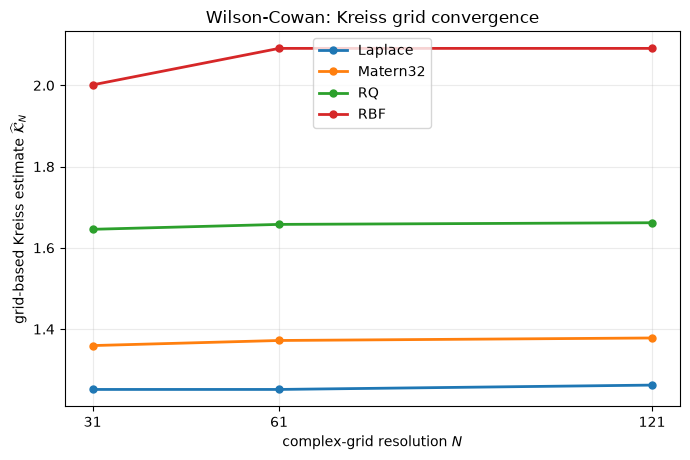

Saved: WilsonCowan_kernel_koopman_results/WC_kreiss_grid_convergence.pdf


In [35]:
# ============================================================
# Kreiss grid-convergence figure
# ============================================================

fig, ax = plt.subplots(
    figsize=(7.0, 4.7)
)

for kind in KERNELS:

    sub = (
        kreiss_conv[
            kreiss_conv["kernel"] == kind
        ]
        .sort_values("grid_n")
    )

    ax.plot(
        sub["grid_n"],
        sub["kreiss_hat"],
        marker="o",
        linewidth=2.0,
        markersize=5,
        label=kind,
    )


ax.set_xlabel(
    "complex-grid resolution $N$"
)

ax.set_ylabel(
    r"grid-based Kreiss estimate "
    r"$\widehat{\mathcal{K}}_N$"
)

ax.set_title(
    f"{SYSTEM_NAME}: Kreiss grid convergence"
)

ax.set_xticks(
    GRID_SIZES
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=True
)

plt.tight_layout()

figure_path = os.path.join(
    OUTDIR,
    f"{FILE_PREFIX}_kreiss_grid_convergence.pdf",
)

plt.savefig(
    figure_path,
    dpi=500,
    bbox_inches="tight",
)

plt.show()

print(
    "Saved:",
    figure_path,
)